Objectives:

**Importing necessary Modules**:
- Import the modules necessary for Data Manipulation and Visualization.

**Reading dataset**:
- Read the dataset containing loan applicant information.

**Task 1 - Exploring the Dataset**:
- Understand the Structure and various datatypes of the attributes within the dataset.

**Task 2 - Missing value analysis**:
- Identify and analyze missing values in the dataset.

**Task 3 - Analysing categorical and numerical columns**:
- Analyze categorical and numerical columns to understand the statistical properties and relationships within the dataset.

**Task 4 - Univariate Analysis**:
- Conduct univariate analysis to explore the distribution and characteristics of individual variables.

**Task 5 - Outliers**:
- Identify and analyze outliers within the dataset to understand their impact on the analysis.

**Task 6 - Merging Datasets**:
- Identify and merge different Datasets for further analysis.

**Task 7 - Bivariate analysis**:
- Conduct bivariate analysis to explore relationships between different variables and their impact on loan default rates.

#Importing necessary Modules

In [1]:
#Importing necessary Libraries for data analysis and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(color_codes = True)

In [ ]:
import warnings
#filter out warnings to ignore them
warnings.filterwarnings('ignore')

# Read the Dataset


In [ ]:
# Read the CSV file 'application_data' into a DataFrame.
application_data = pd.read_csv('/content/application_data.csv')

#Task 1 - Exploring the Data

In [ ]:
# Display the first few rows of the DataFrame.
application_data.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Get the Dimensions of the DataFrame (number of rows and columns)
application_data.shape

(307511, 122)

In [ ]:
# Get the concise summary of information about the DataFrame.
application_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [ ]:
application_data.iloc[:,:100].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98949 entries, 0 to 98948
Data columns (total 100 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   SK_ID_CURR                    98949 non-null  int64  
 1   TARGET                        98949 non-null  int64  
 2   NAME_CONTRACT_TYPE            98949 non-null  object 
 3   CODE_GENDER                   98949 non-null  object 
 4   FLAG_OWN_CAR                  98949 non-null  object 
 5   FLAG_OWN_REALTY               98949 non-null  object 
 6   CNT_CHILDREN                  98949 non-null  int64  
 7   AMT_INCOME_TOTAL              98949 non-null  float64
 8   AMT_CREDIT                    98949 non-null  float64
 9   AMT_ANNUITY                   98942 non-null  float64
 10  AMT_GOODS_PRICE               98868 non-null  float64
 11  NAME_TYPE_SUITE               98551 non-null  object 
 12  NAME_INCOME_TYPE              98949 non-null  object 
 13  

In [ ]:
application_data.iloc[:,100:122].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98949 entries, 0 to 98948
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   FLAG_DOCUMENT_6             98948 non-null  float64
 1   FLAG_DOCUMENT_7             98948 non-null  float64
 2   FLAG_DOCUMENT_8             98948 non-null  float64
 3   FLAG_DOCUMENT_9             98948 non-null  float64
 4   FLAG_DOCUMENT_10            98948 non-null  float64
 5   FLAG_DOCUMENT_11            98948 non-null  float64
 6   FLAG_DOCUMENT_12            98948 non-null  float64
 7   FLAG_DOCUMENT_13            98948 non-null  float64
 8   FLAG_DOCUMENT_14            98948 non-null  float64
 9   FLAG_DOCUMENT_15            98948 non-null  float64
 10  FLAG_DOCUMENT_16            98948 non-null  float64
 11  FLAG_DOCUMENT_17            98948 non-null  float64
 12  FLAG_DOCUMENT_18            98948 non-null  float64
 13  FLAG_DOCUMENT_19            989

#Task 2 - Missing Values Analysis

### Calculating the Percentage of Missing values

In [ ]:
# calculate the percentage of missing values
value_missing = (application_data.isnull().sum()/len(application_data))*100

# sort the missing percentage in descending order
value_missing.sort_values(ascending = False).head(60)

,0
COMMONAREA_AVG,69.766243
COMMONAREA_MODE,69.766243
COMMONAREA_MEDI,69.766243
NONLIVINGAPARTMENTS_MEDI,69.314495
NONLIVINGAPARTMENTS_MODE,69.314495
NONLIVINGAPARTMENTS_AVG,69.314495
LIVINGAPARTMENTS_AVG,68.309937
LIVINGAPARTMENTS_MODE,68.309937
LIVINGAPARTMENTS_MEDI,68.309937
FONDKAPREMONT_MODE,68.252332


###Missing Value Treatment

As you can observe, there are lot of columns with missing values. There are some columns which has missing values around or more than 50%. Other columns has significantly less missing value. Also, the columns for which has missing values are around or more than 50% are mostly either mean, median or mode. So, there is no way one can replace these missing data. So, we will not consider these columns for analysis. We will consider other columns for analysis. Let's analyse the other columns.

###Removing the columns with more then 50% missing values

In [ ]:
# filter the DataFrame 'application_data' to include only columns with less than 50% missing values
data = application_data.loc[:, value_missing < 50]

In [ ]:
# calculate the percentage of missing values for each column
value_missing_2 = (data.isnull().sum()/len(data))*100

# Sort the missing percentages in descending order
value_missing_2[value_missing_2 > 0].sort_values(ascending=False)

,0
FLOORSMAX_MODE,49.722584
FLOORSMAX_AVG,49.722584
FLOORSMAX_MEDI,49.722584
YEARS_BEGINEXPLUATATION_AVG,48.738239
YEARS_BEGINEXPLUATATION_MODE,48.738239
YEARS_BEGINEXPLUATATION_MEDI,48.738239
TOTALAREA_MODE,48.256172
EMERGENCYSTATE_MODE,47.374910
OCCUPATION_TYPE,31.228208
EXT_SOURCE_3,19.824354


In [ ]:
# OCCUPATION_TYPE               	31.345545
# EXT_SOURCE_3                  	19.825307
# AMT_REQ_CREDIT_BUREAU_QRT      	13.501631
# AMT_REQ_CREDIT_BUREAU_YEAR	    13.501631
# AMT_REQ_CREDIT_BUREAU_WEEK	    13.501631
# AMT_REQ_CREDIT_BUREAU_DAY     	13.501631
# AMT_REQ_CREDIT_BUREAU_HOUR	    13.501631
# AMT_REQ_CREDIT_BUREAU_MON	      13.501631
# NAME_TYPE_SUITE                	 0.420148
# OBS_30_CNT_SOCIAL_CIRCLE	       0.332021
# OBS_60_CNT_SOCIAL_CIRCLE	       0.332021
# DEF_30_CNT_SOCIAL_CIRCLE	       0.332021
# DEF_60_CNT_SOCIAL_CIRCLE	       0.332021
# EXT_SOURCE_2	                   0.214626
# AMT_GOODS_PRICE	                 0.090403
# AMT_ANNUITY                      0.003902
# CNT_FAM_MEMBERS	                 0.000650
# DAYS_LAST_PHONE_CHANGE	         0.000325

Let's analylize these columns one by one :

###Column : OCCUPATION_TYPE

The OCCUPATION_TYPE column has a large amount of missing data, about 31%. Although this might suggest removing the column, when we look at it closely, it seems to be an important piece of information. So, we've chosen to keep the column and not analyze it further.

In [ ]:
# Display the first few.
data['OCCUPATION_TYPE'].head()

,OCCUPATION_TYPE
0,Laborers
1,Core staff
2,Laborers
3,Laborers
4,Core staff


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
 [Text(0, 0, 'Laborers'),
  Text(1, 0, 'Core staff'),
  Text(2, 0, 'Accountants'),
  Text(3, 0, 'Managers'),
  Text(4, 0, 'Drivers'),
  Text(5, 0, 'Sales staff'),
  Text(6, 0, 'Cleaning staff'),
  Text(7, 0, 'Cooking staff'),
  Text(8, 0, 'Private service staff'),
  Text(9, 0, 'Medicine staff'),
  Text(10, 0, 'Security staff'),
  Text(11, 0, 'High skill tech staff'),
  Text(12, 0, 'Waiters/barmen staff'),
  Text(13, 0, 'Low-skill Laborers'),
  Text(14, 0, 'Realty agents'),
  Text(15, 0, 'Secretaries'),
  Text(16, 0, 'IT staff'),
  Text(17, 0, 'HR staff')])

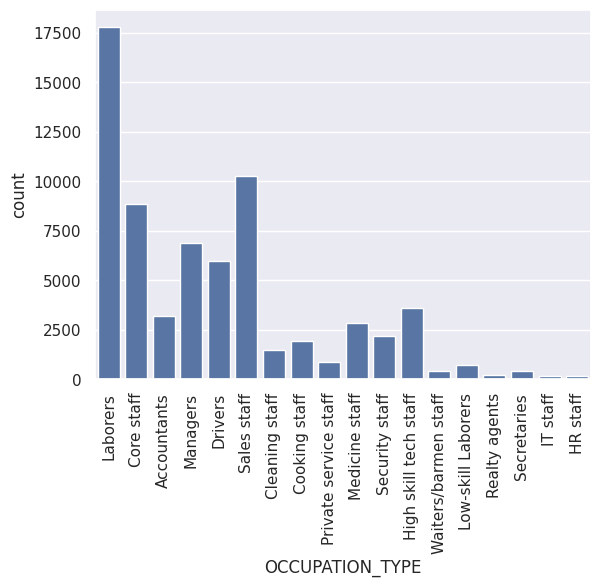

In [ ]:
#application_train['OCCUPATION_TYPE'].count.plot.hist()
sns.countplot(x= 'OCCUPATION_TYPE', data = data)
plt.xticks(rotation=90)

###Column: EXT_SOURCE_3

In [ ]:
# Display the first few.
data['EXT_SOURCE_3'].head()

,EXT_SOURCE_3
0,0.139376
1,NaN
2,0.729567
3,NaN
4,NaN


<Axes: ylabel='Frequency'>

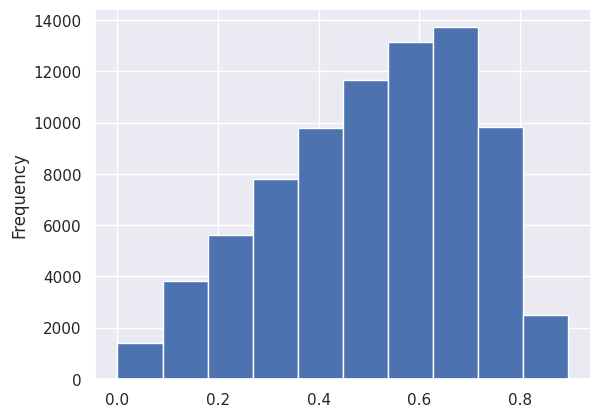

In [ ]:
# Plotting the distribution
data['EXT_SOURCE_3'].plot.hist()

In [ ]:
# Calculate the mean
data['EXT_SOURCE_3'].mean()

np.float64(0.5103879724112239)

In [ ]:
# Calculate the mode
data['EXT_SOURCE_3'].mode()

,EXT_SOURCE_3
0,0.7463


###Column : DAYS_BIRTH

This column represents the client's age in days relative to the application date, displayed as negative values. For clarity and ease of understanding, we are converting these values into years. We use the -round() function to transform the negative values into positive ones. We plan to apply the same transformation method to other date-related data.

In [ ]:
# Display the first few rows of the 'DAYS_BIRTH' column in the DataFrame 'data'
data['DAYS_BIRTH'].head()

,DAYS_BIRTH
0,-9461
1,-16765
2,-19046
3,-19005
4,-19932


In [ ]:
# Convert the values in the 'DAYS_BIRTH' column from days to years and display the first few rows
data['DAYS_BIRTH'] = -round(data['DAYS_BIRTH'] / 365)
data['DAYS_BIRTH'].head()

,DAYS_BIRTH
0,26.0
1,46.0
2,52.0
3,52.0
4,55.0


In [ ]:
# Convert the values in the 'DAYS_REGISTRATION' column from days to years and display the first few rows
data['DAYS_REGISTRATION'] = -round(data['DAYS_REGISTRATION'] / 365, 0) # 0 is used for decimal value
data['DAYS_REGISTRATION'].head()

,DAYS_REGISTRATION
0,10.0
1,3.0
2,12.0
3,27.0
4,12.0


In [ ]:
# Convert the values in the 'DAYS_ID_PUBLISH' column from days to years and display the first few rows
data['DAYS_ID_PUBLISH'] = -round(data['DAYS_ID_PUBLISH']/ 365, 0)
data['DAYS_ID_PUBLISH'].head()

,DAYS_ID_PUBLISH
0,6.0
1,1.0
2,7.0
3,7.0
4,9.0


In [ ]:
# get the datatypes of each column in the DataFrame 'data'
data.dtypes

,0
SK_ID_CURR,int64
TARGET,int64
NAME_CONTRACT_TYPE,object
CODE_GENDER,object
FLAG_OWN_CAR,object
...,...
AMT_REQ_CREDIT_BUREAU_DAY,float64
AMT_REQ_CREDIT_BUREAU_WEEK,float64
AMT_REQ_CREDIT_BUREAU_MON,float64
AMT_REQ_CREDIT_BUREAU_QRT,float64


In a similar manner, we can do analysis for other columns.

###Ratio

In [ ]:
# Calculate the ratio of records with 'TARGET' == 0 to records with 'TARGET' == 1.
(data['TARGET'] == 0).sum() / (data['TARGET'] == 1).sum()

np.float64(11.342397405513283)

There is too much data imbalance in the dataset.

#Task 3 - Analysing Categorical and Numerical Data

### Analysing Categorial Data

Due to imbalance data, we will separate out the data with a Target equal to 0 and data with a Target equal to 1.And we will analyse them individually.

In [ ]:
# Create a subset containing records where the 'Target' column equal to 0
data_0 = data[data['TARGET'] == 0]

# Create a subset containing records where the 'Target' column equal to 1
data_1 = data[data['TARGET'] == 1]

We utilized three distinct plots for analysis:

**Pie plot:**


* This displays all the values present in a column as percentages, where the sum of these percentages equals 100.

**Countplot:**

* Here, we depicted the count of different categories. Consequently, Target=0 will typically have a higher count than Target=1.

**Barplot:**

* To create this plot, we initially divided the dataset into two subsets based on the target variable: Target=0 and Target=1. Next, we further subdivided each subset into different categories. We then plotted these categories as percentages. Notably, you'll observe that the values for Target=0 and Target=1 are mostly equal. For a deeper understanding, please refer to the code of this plot.



In [ ]:
def plotting (data, data_0, data_1, column):
    """
    Plots three types of visualizations for a given column in the dataset:
    a pie chart of overall distribution,
    a countplot by category, and
    a bar plot of percentage distribution by target variable.

    Parameters:
    - train: DataFrame containing the entire dataset.
    - train0: DataFrame filtered by the target variable with value 0.
    - train1: DataFrame filtered by the target variable with value 1.
    - column: The name of the column to be visualized.
    """

    # Initialize figure with a specific size
    fig = plt.figure(figsize=(13,10))

    # Create a subplot for the pie chart
    ax1 = plt.subplot(2,2,1)
     # Plotting pie chart for overall distribution of the column
    data[column].value_counts().plot.pie(autopct="%1.0f%%", ax=ax1)
    plt.title('Plotting data for the column: ' + column)

    # Create a subplot for the countplot
    ax2 = plt.subplot(2,2,2)
    # Plotting count plot by category with hue as TARGET
    sns.countplot(x=column, hue='TARGET', data= data, ax=ax2)
    plt.xticks(rotation=90)
    plt.title('Plotting data for target in terms of total count')

    # Create a subplot for the bar plot
    ax3 = plt.subplot(2,2,3)
    # Preparing data for percentage distribution by target variable
    df = pd.DataFrame()
    df['0'] = ((data_0[column].value_counts())/len(data_0))
    df['1'] = ((data_1[column].value_counts())/len(data_1))
    # Plotting bar plot for percentage distribution
    df.plot.bar(ax=ax3)
    plt.title('Plotting data for target in terms of percentage')

    # Display the plots
    plt.show()

In [ ]:
# Create a list to get all the Categorical columns
data_categorical = data.select_dtypes(include = ['object']).columns
data_categorical

Index(['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE',
       'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE',
       'EMERGENCYSTATE_MODE'],
      dtype='object')

#Task 4.1 - Univariate Analysis of the Categorical data

Visualising Data Distribution

Take, for instance, the column "NAME_CONTRACT_TYPE". The visualisations produced offer insightful data distributions:

Pie Chart (First Plot):

* It reveals that 90% of the entries are
'Cash loans', while the remaining 10% are 'Revolving loans'.

Count Plot (Second Plot):

* This visualization differentiates between 'Cash loans' and 'Revolving loans' based on the TARGET variable. For TARGET=0 (no default), there are approximately 250,000 'Cash loans' and around 2,500 'Revolving loans'. The plot offers a similar breakdown for TARGET=1 (default), enabling a comparison of counts between the two TARGET categories.

Percentage Bar Plot (Third Plot):

* In this plot, the data is presented in terms of percentage, focusing on the relative distribution within each TARGET category. The 'Cash loans' and 'Revolving loans' are stacked (in blue for TARGET=0 and orange for TARGET=1).

Plotting NAME_CONTRACT_TYPE


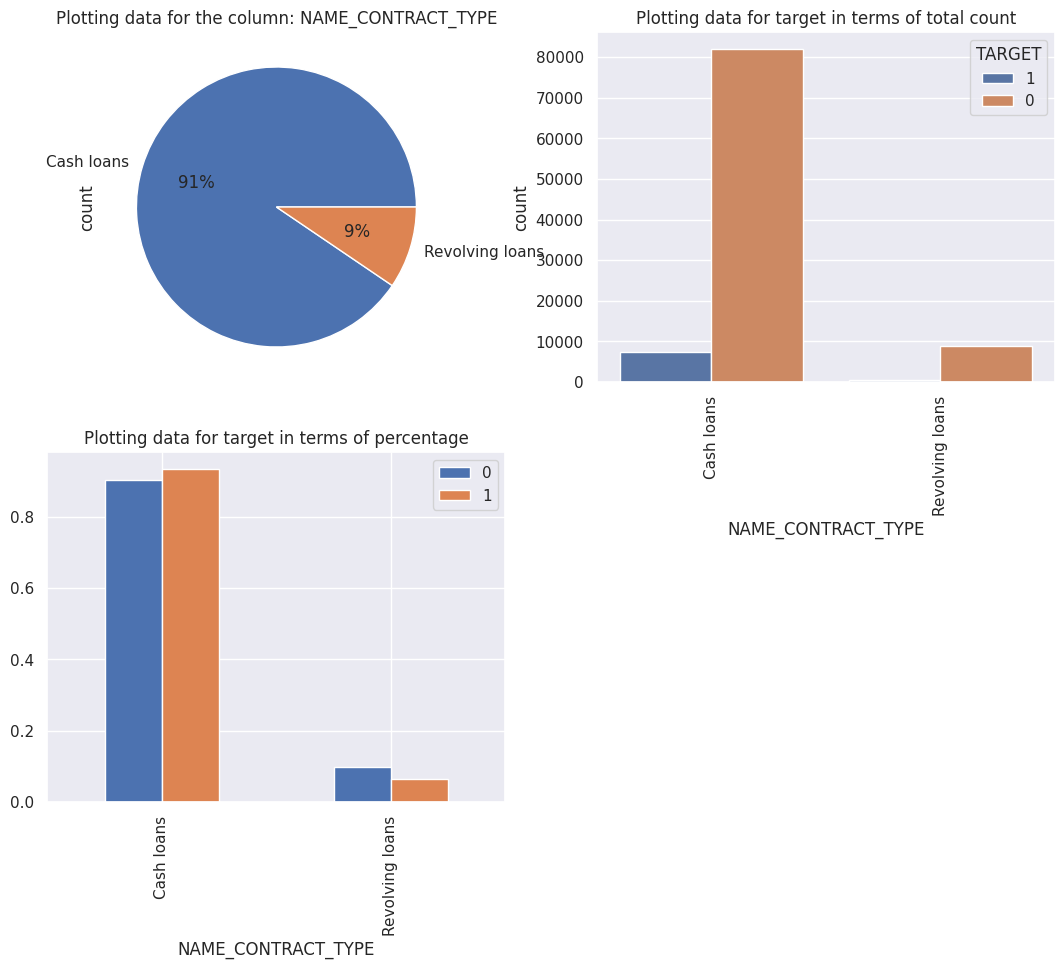

----------------------------------------------------------------------------------------------
Plotting CODE_GENDER


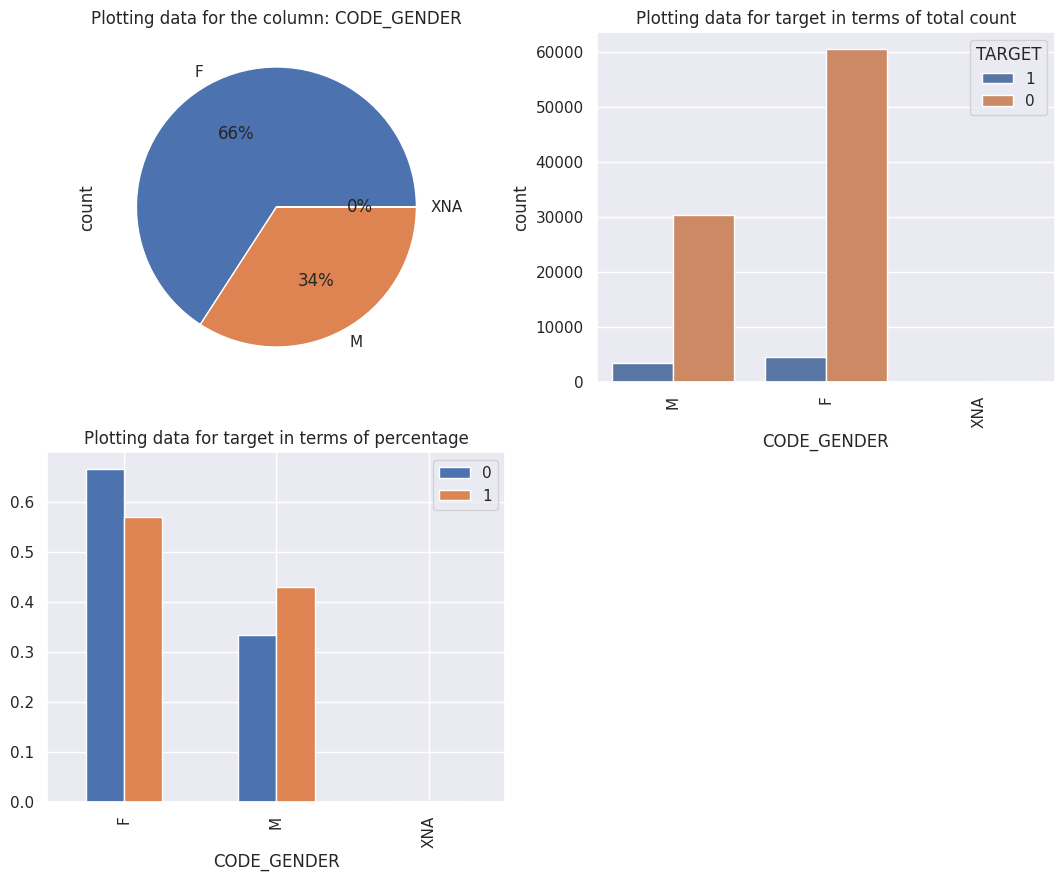

----------------------------------------------------------------------------------------------
Plotting FLAG_OWN_CAR


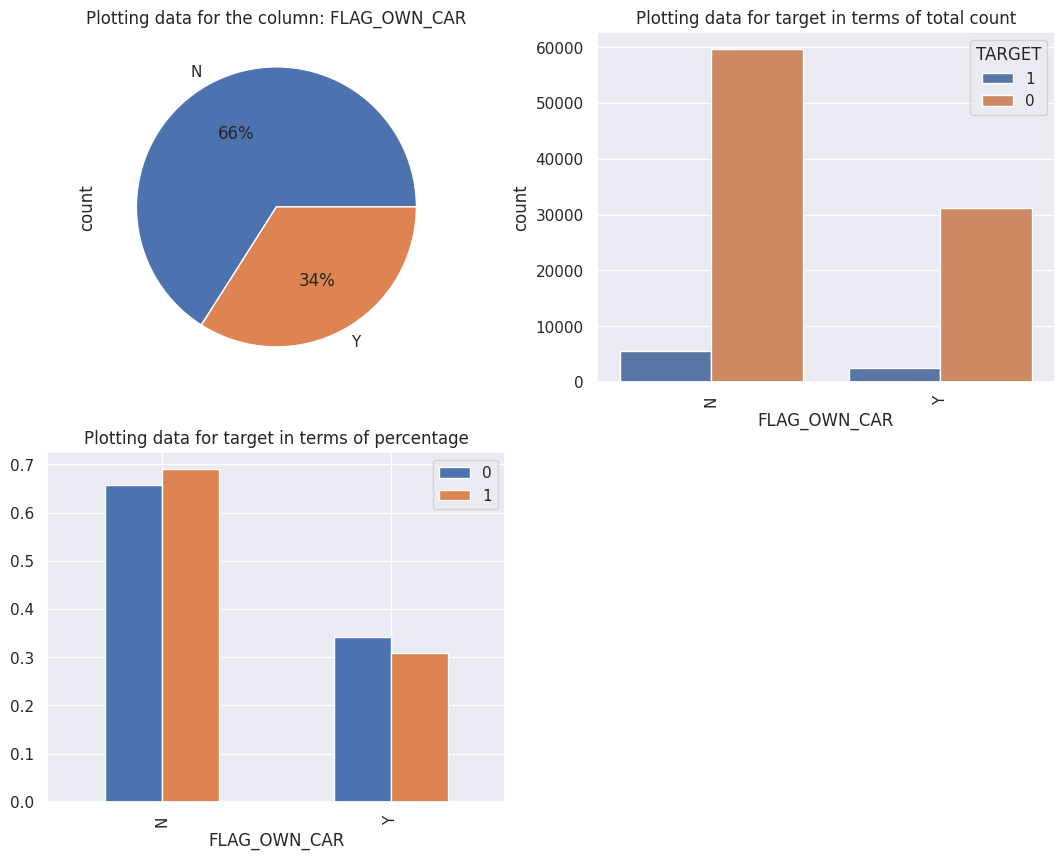

----------------------------------------------------------------------------------------------
Plotting FLAG_OWN_REALTY


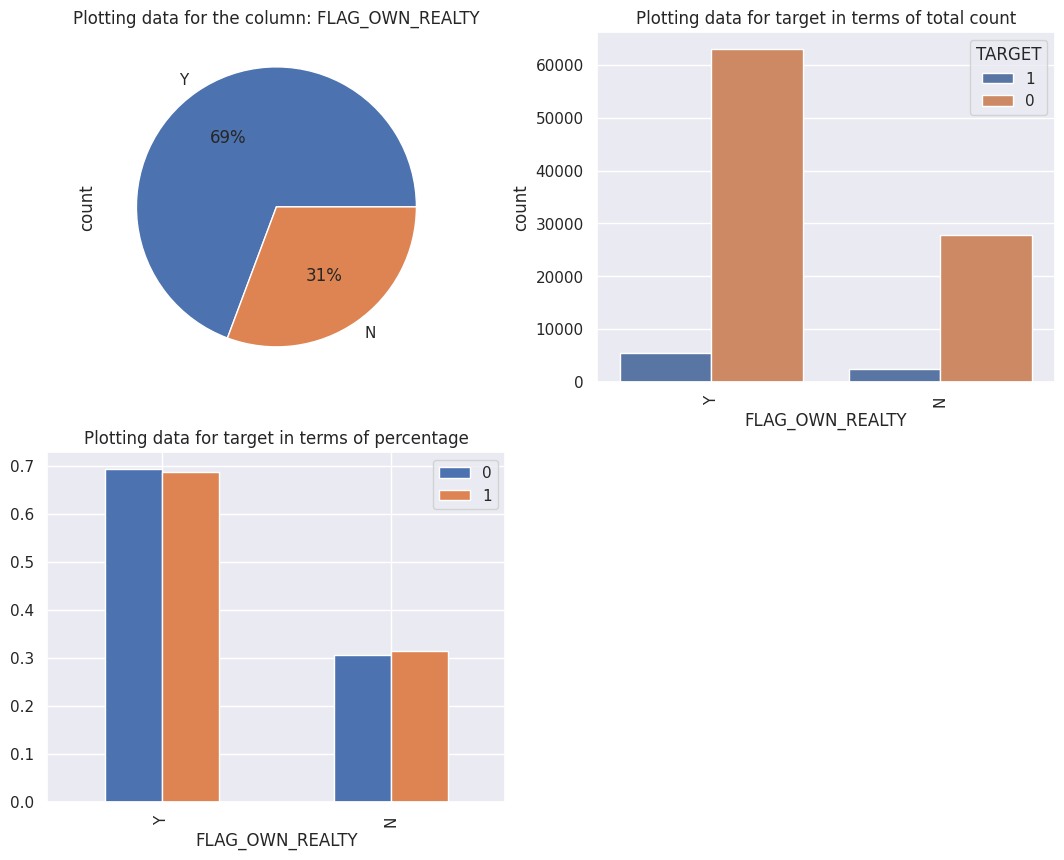

----------------------------------------------------------------------------------------------
Plotting NAME_TYPE_SUITE


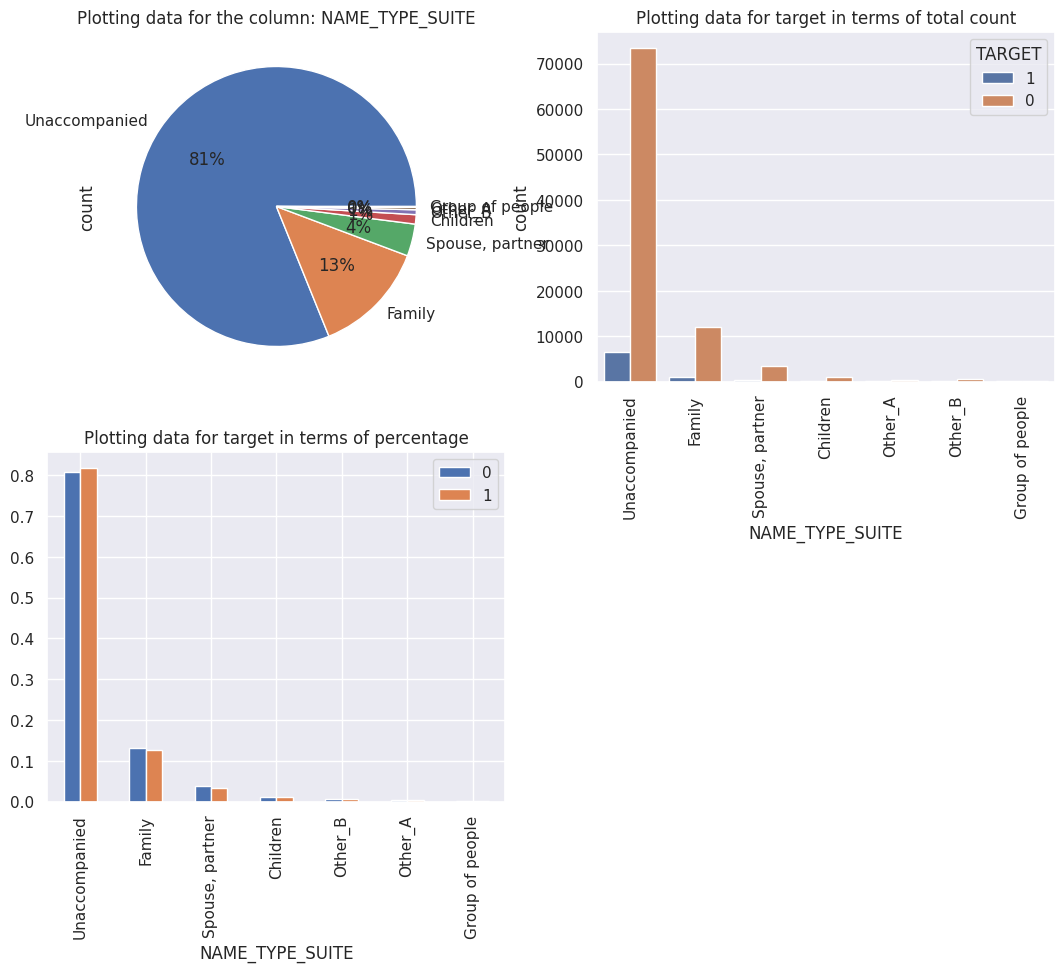

----------------------------------------------------------------------------------------------
Plotting NAME_INCOME_TYPE


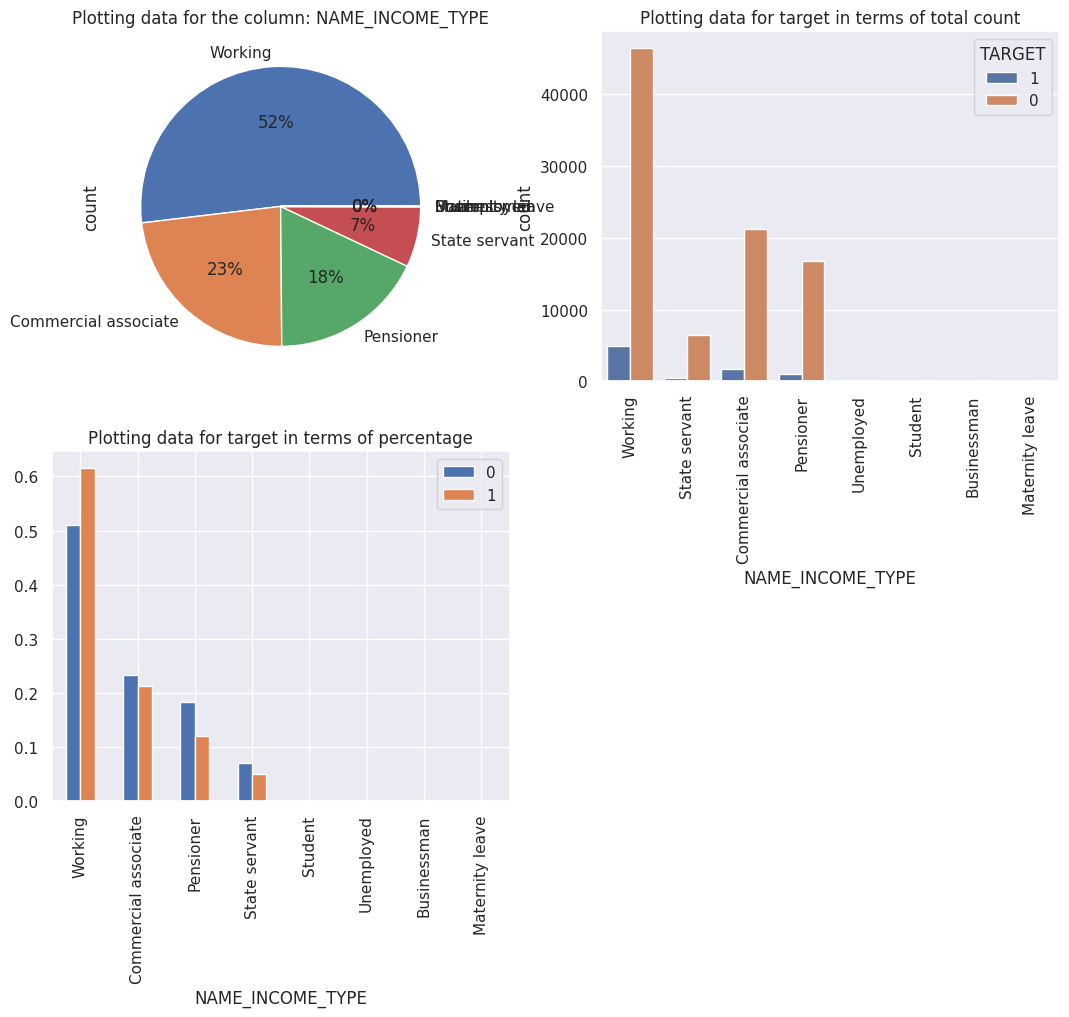

----------------------------------------------------------------------------------------------
Plotting NAME_EDUCATION_TYPE


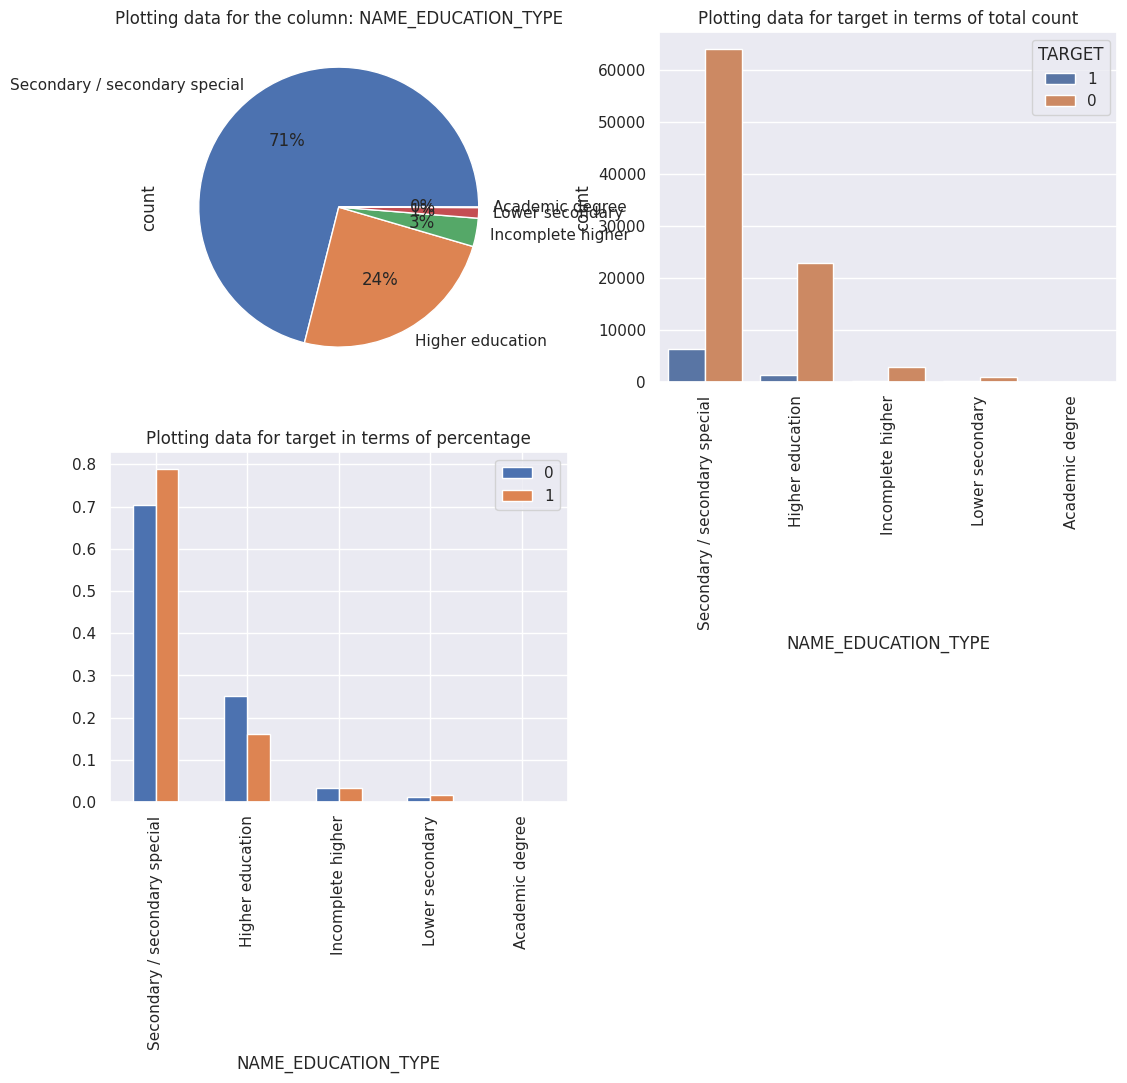

----------------------------------------------------------------------------------------------
Plotting NAME_FAMILY_STATUS


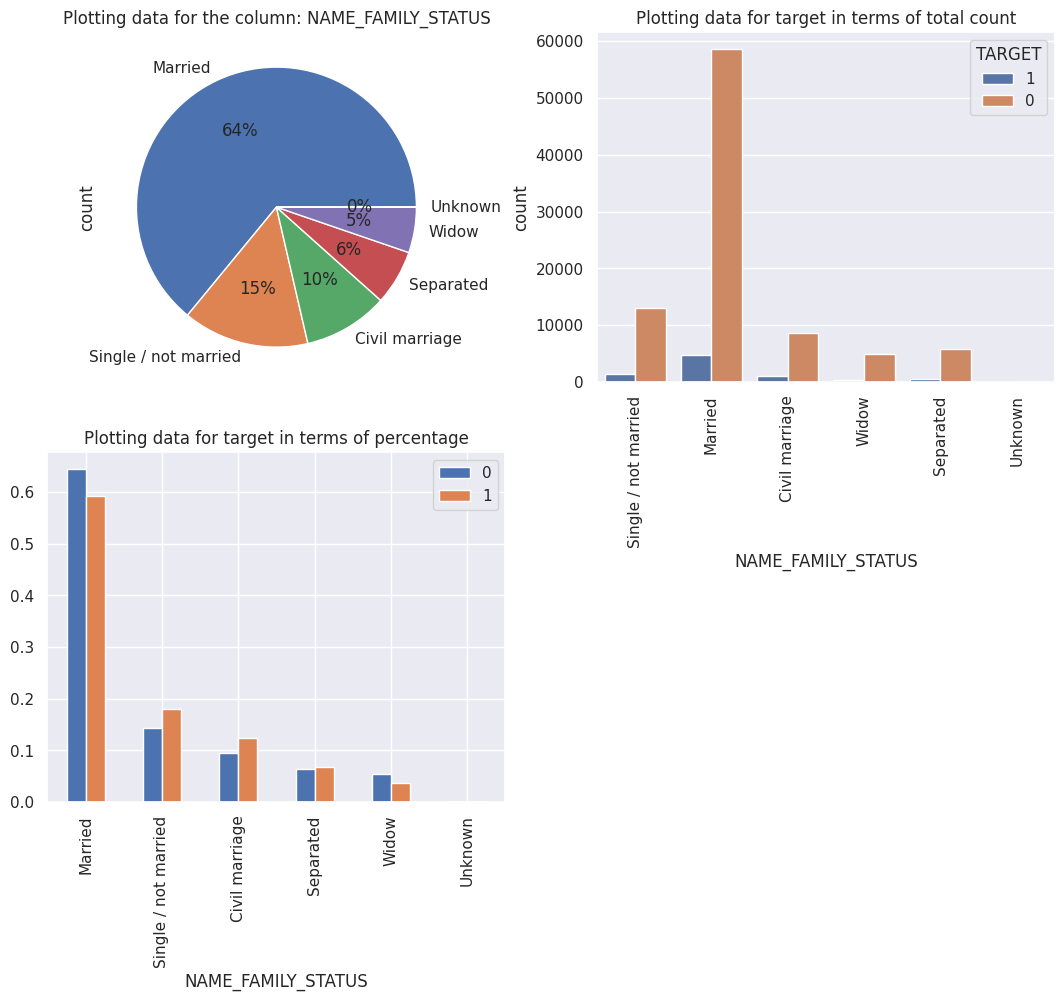

----------------------------------------------------------------------------------------------
Plotting NAME_HOUSING_TYPE


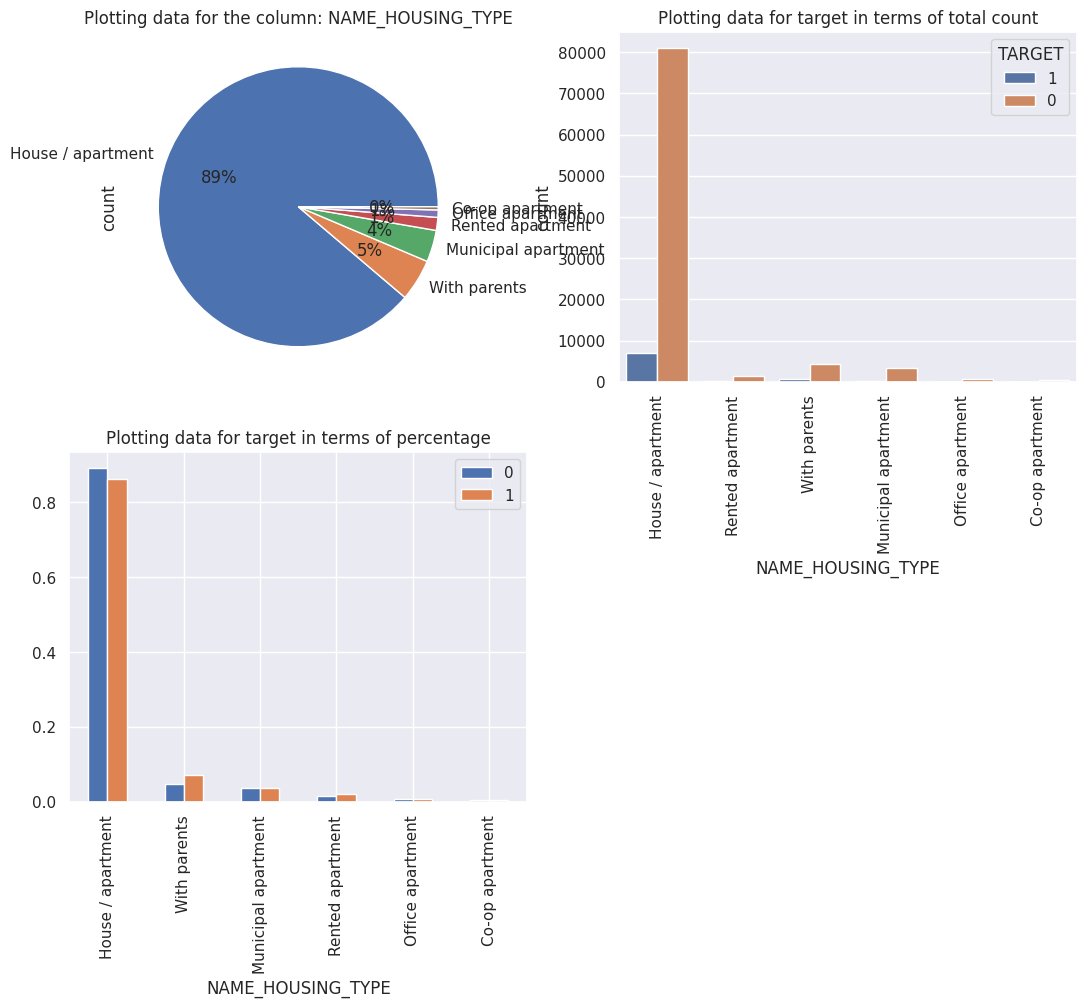

----------------------------------------------------------------------------------------------
Plotting OCCUPATION_TYPE


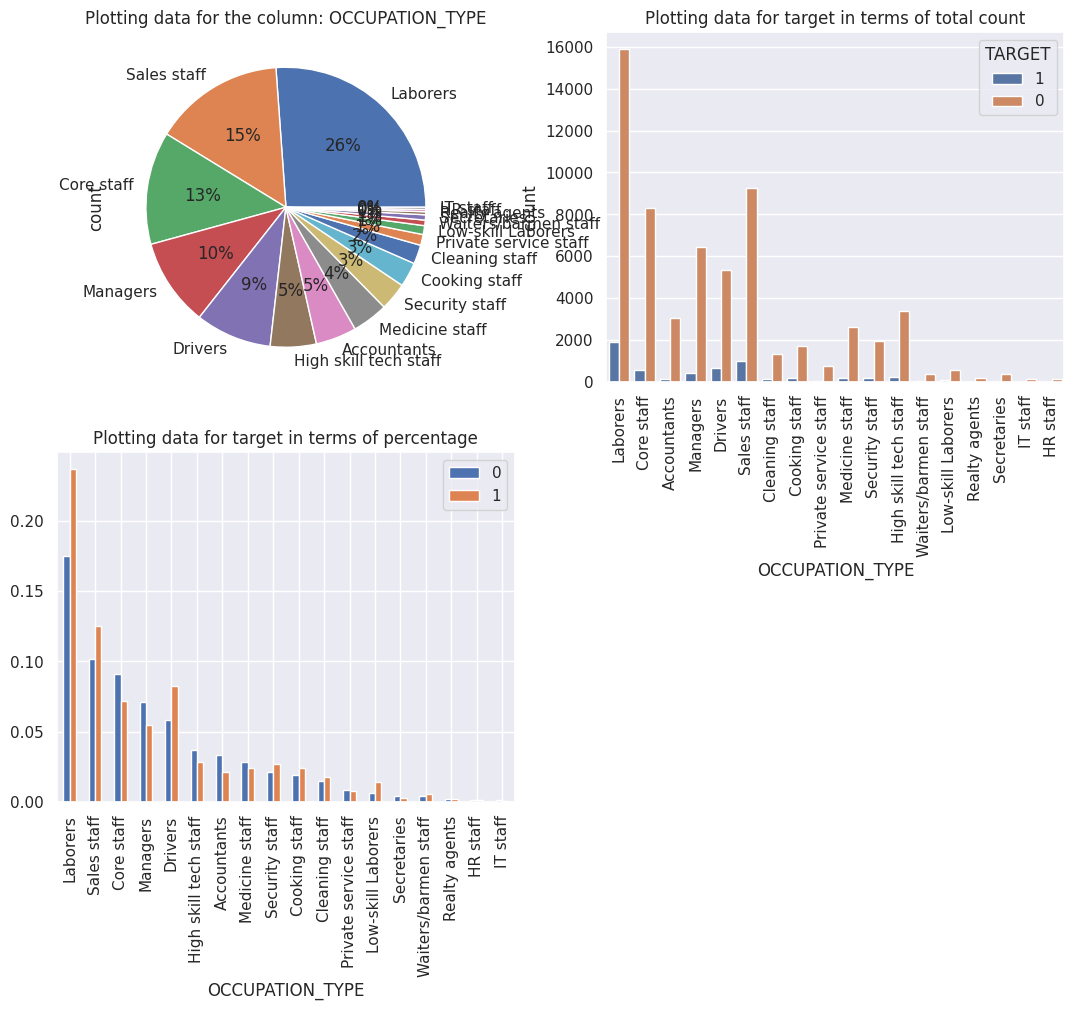

----------------------------------------------------------------------------------------------
Plotting WEEKDAY_APPR_PROCESS_START


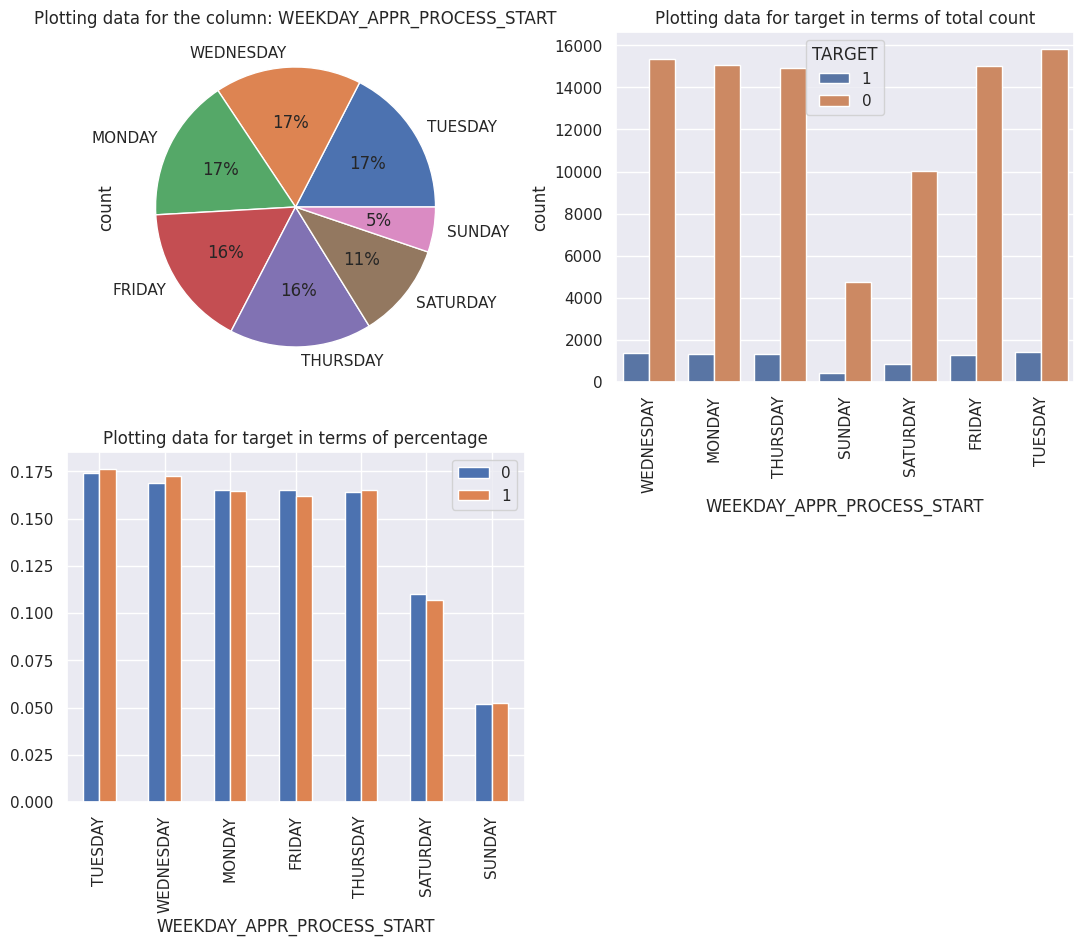

----------------------------------------------------------------------------------------------
Plotting ORGANIZATION_TYPE


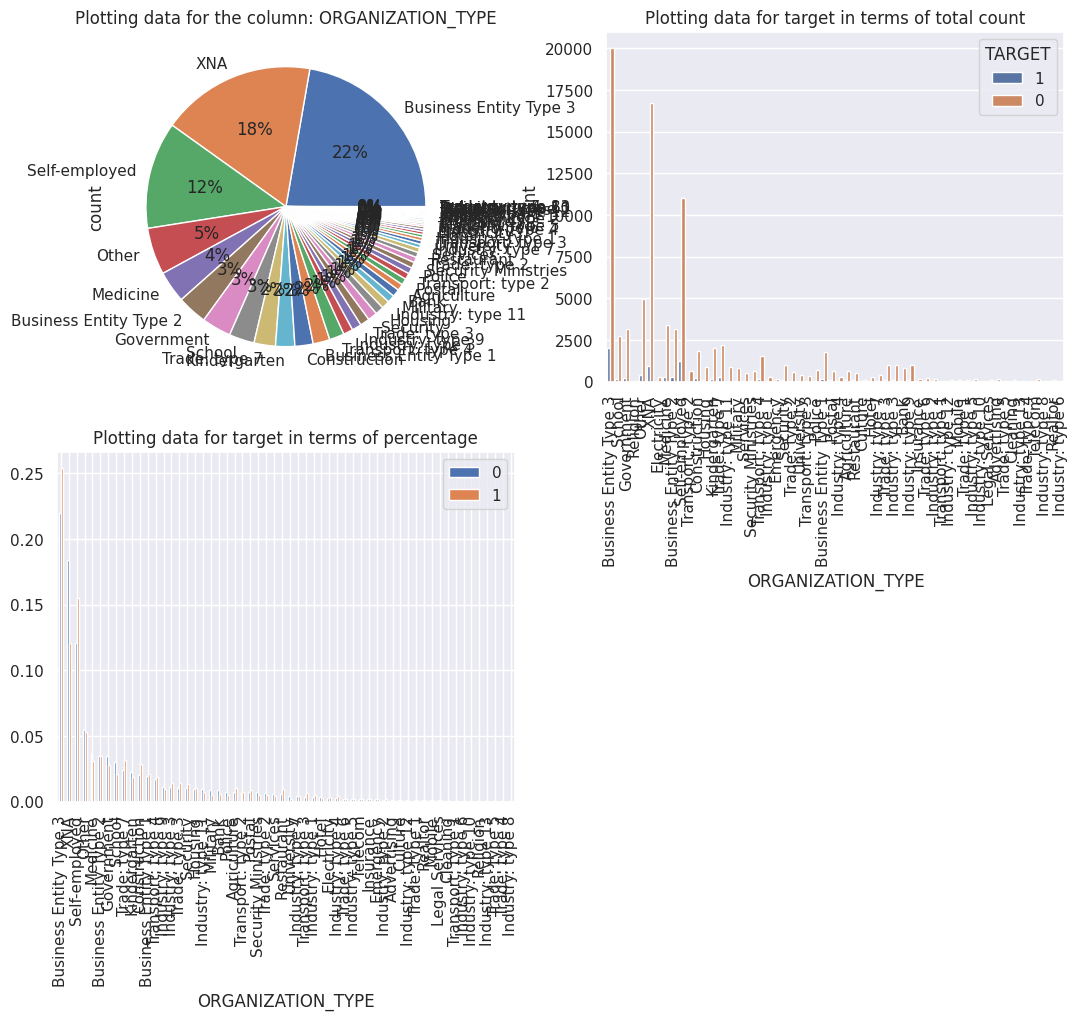

----------------------------------------------------------------------------------------------
Plotting EMERGENCYSTATE_MODE


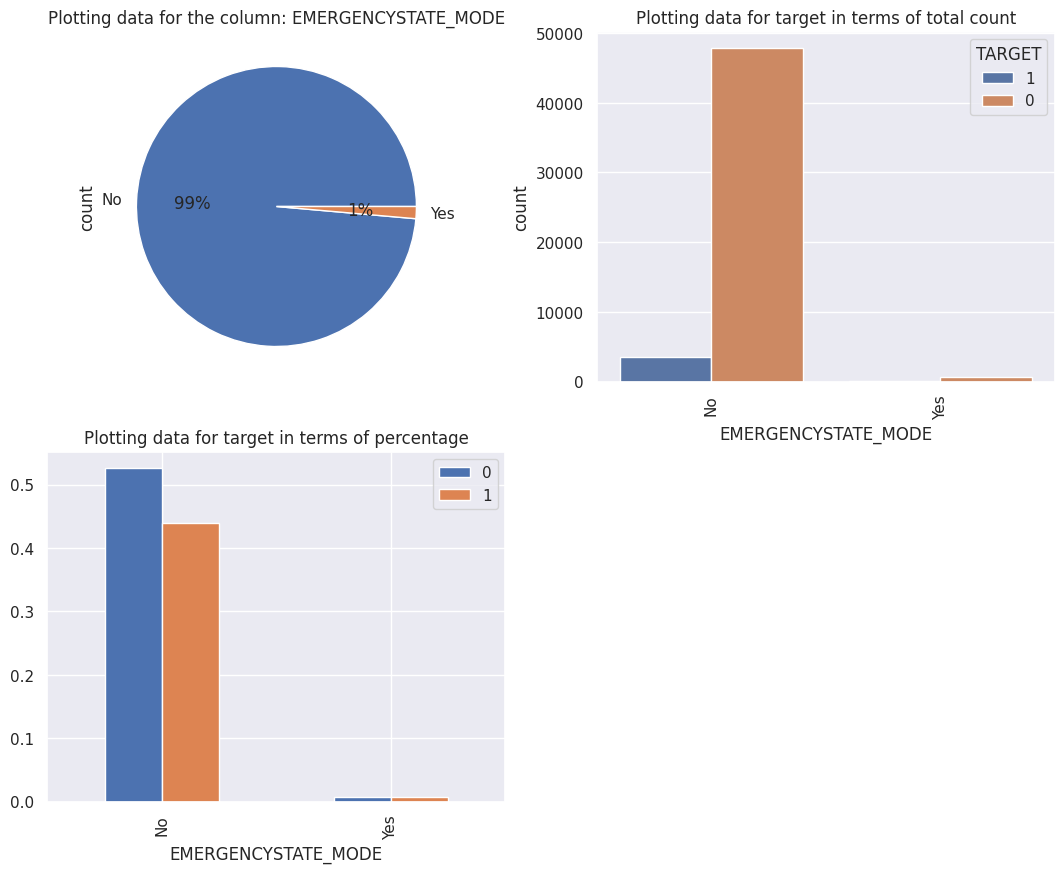

----------------------------------------------------------------------------------------------


In [ ]:
# Convert 'Target' to a string data type for categorical processing.
data['TARGET'] = data['TARGET'].astype(str)

# Change 'NAME_CONTRACT_TYPE' to a categorical type for optimized storage and plotting.
data['NAME_CONTRACT_TYPE'] = data['NAME_CONTRACT_TYPE'].astype('category')

# Iterate through a list of categorical column names, creating plots for each.
for column in data_categorical:
   print('Plotting', column)

   # Generate visualizations for the current column against the TARGET variable.
   plotting(data, data_0, data_1, column)

   # Prints a separator line for readability between plots of different columns.
   print('----------------------------------------------------------------------------------------------')



The analysis identifies several key variables that significantly influence loan behavior and default rates:

CODE_GENDER:
- Although loans are less frequently taken by males, the data indicates that the proportion of male defaulters is notably higher compared to females. This suggests gender as a potential factor in assessing loan risk.

NAME_INCOME_TYPE:
- Pensioners show a lower default rate, implying that despite a potentially fixed or lower income, they maintain a higher reliability in repaying loans.

NAME_EDUCATION_TYPE:
- Loans are predominantly sought for secondary education, followed by higher education. However, the default rate among borrowers with secondary education is substantially higher than those with higher education credentials. This points to education level as a significant determinant of loan repayment capacity.

NAME_FAMILY_STATUS:
- Married individuals are the most common applicants for loans and tend to have lower default rates. In contrast, singles and those in civil marriages exhibit higher default rates, highlighting the influence of marital status on loan repayment behavior.

OCCUPATION_TYPE:
- Laborers and various staff categories are the most frequent loan applicants, yet managers and high-skilled tech staff prove to be the most reliable in terms of repayment. This underscores the role of occupation type in predicting loan default risk.

We can also analyse the numerical columns for defaulters and non-defaulters separately to identify correlations among variables.

In [ ]:
# Select columns with numerical data types ('int64' and 'float64') from the DataFrame 'data'
data_categorical = data.select_dtypes(include=['int64', 'float64']).columns

#Task 4.2 - Univariate Analysis of the Numerical data

For univariate analysis of the numerical columns, we will plot the histogram and the distribution plot.

In [ ]:
# Iterate over each categorical column to generate plots
for column in data_categorical:
    # Construct and print the title for current plot
    title = "Plot of " + column
    print(title)

    # Plot histograms for the distribution of the variable for both TARGET categories
    plt.hist(data_0[column], alpha=0.5, label='Target=0')  # Histogram for category '0'
    plt.hist(data_1[column], alpha=0.5, label='Target=1')  # Histogram for category '1'
    plt.legend()  # Add a legend to distinguish between categories
    plt.show()  # Display the histogram

    # Plot distribution plots for the non-null values in both TARGET categories
    sns.distplot(data_0[column].dropna(), label='Target=0', kde=False, norm_hist=True)  # Distribution plot for '0'
    sns.distplot(data_1[column].dropna(), label='Target=1', kde=False, norm_hist=True)  # Distribution plot for '1'
    plt.legend()  # Add a legend to distinguish between categories
    plt.show()  # Display the distribution plot

    # Print a separator for readability between plots
    print("------------------------------------------------------------------------")

Output hidden; open in https://colab.research.google.com to view.

The columns which seems different where both the histogram and distribution plot are different for the target = 0 and target = 1 are:
- AMT_CREDIT:
- AMT_ANNUITY:
- AMT_GOODS_PRICE
- DAYS_BIRTH
- HOURS_APPR_PROCESS_START
- EXT_SOUCE_2
- EXT_SOURCE_3
- AMT_REQ_CREDIT_BUREAU_YEAR

#Task 5 - Analysis for the outliers

Plotting the numerial data based on the index and analysing if there are outliers in any of the columns:

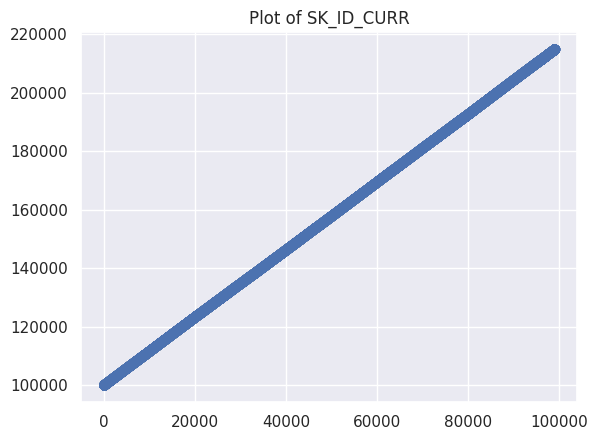

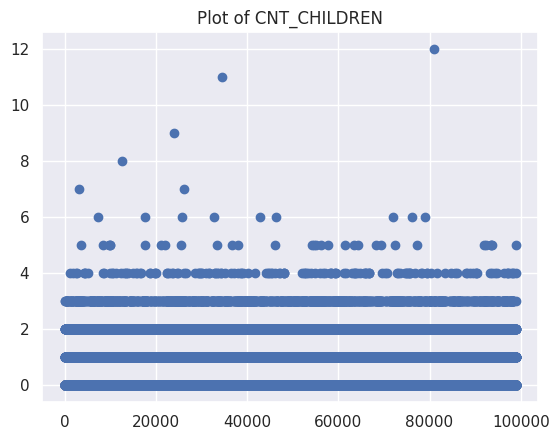

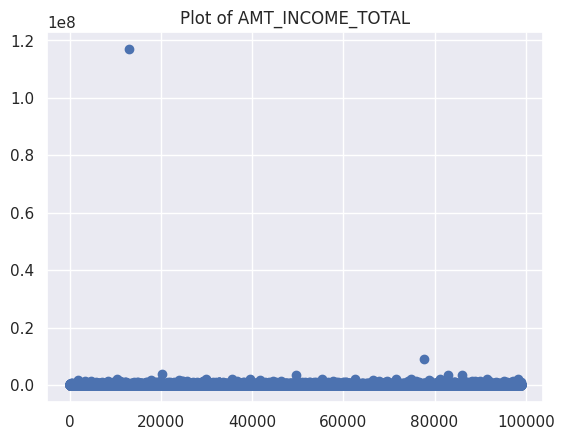

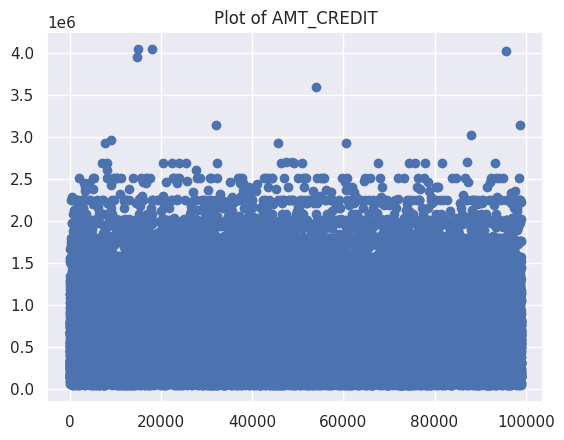

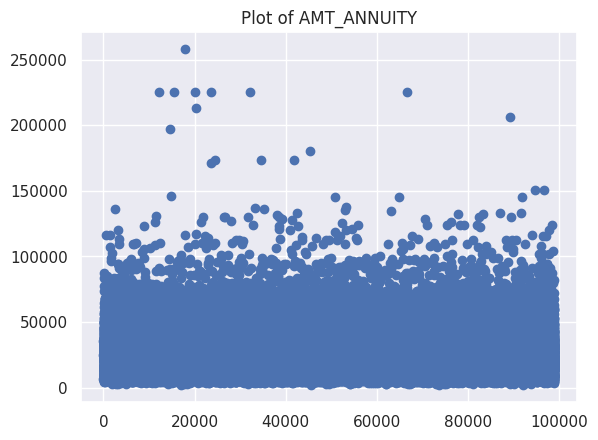

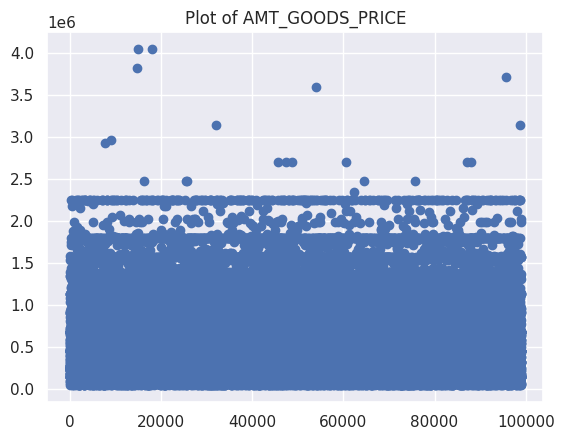

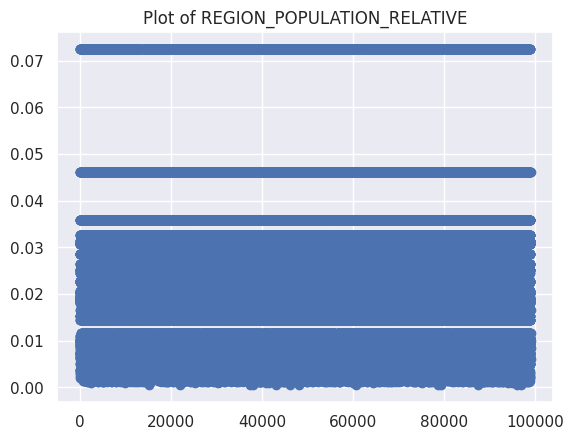

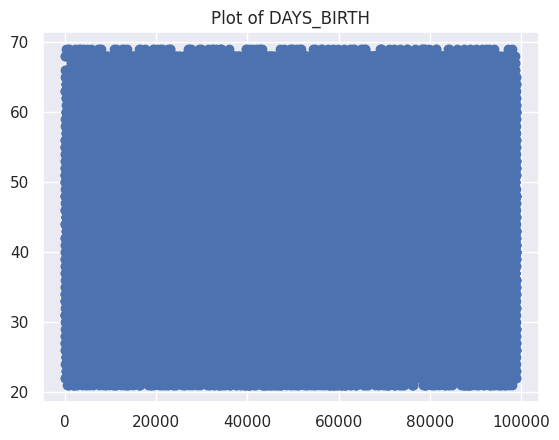

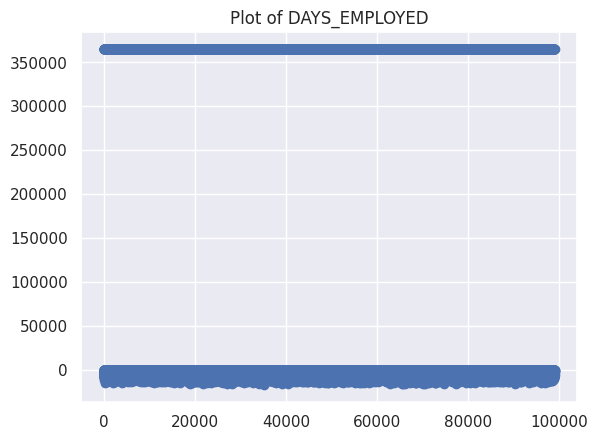

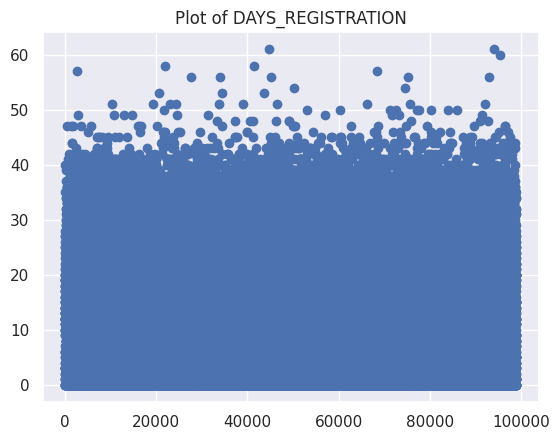

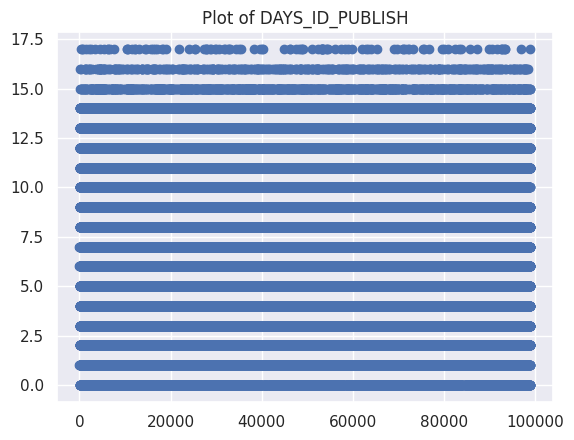

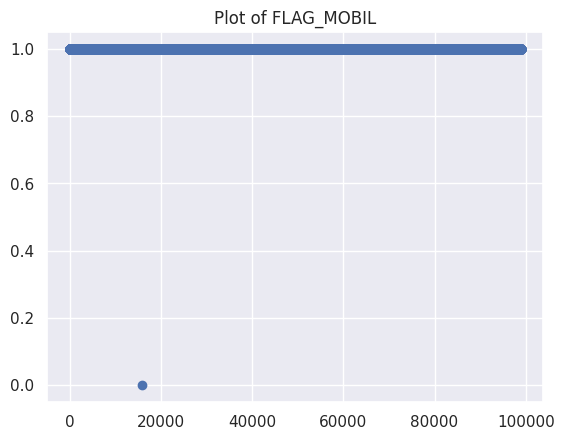

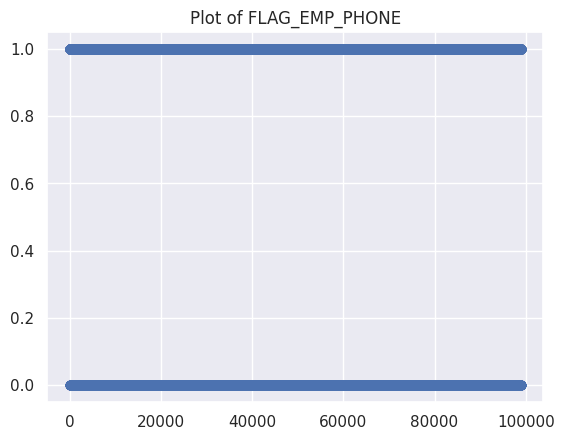

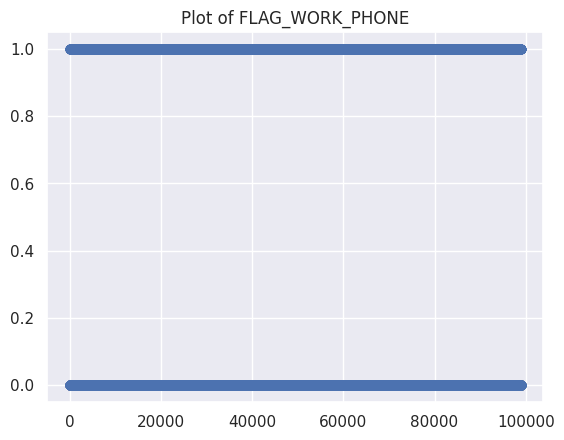

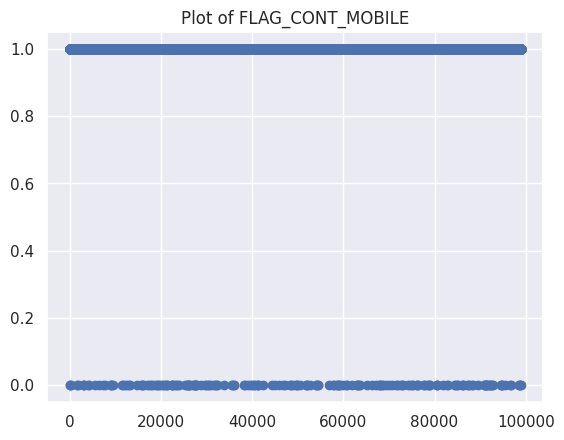

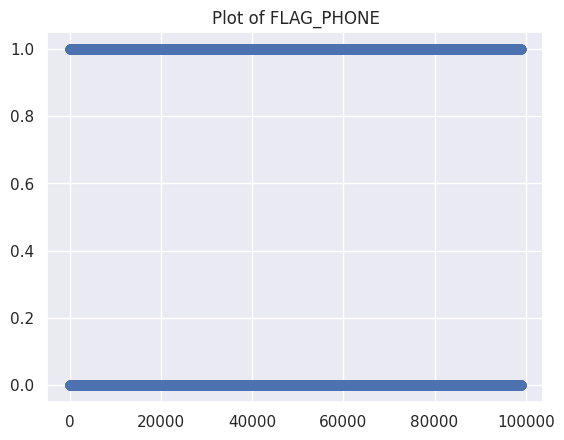

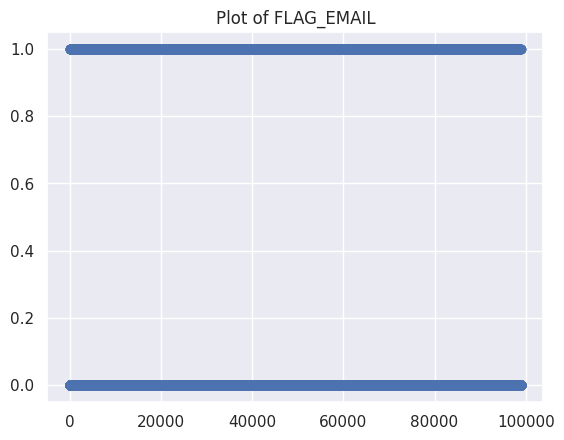

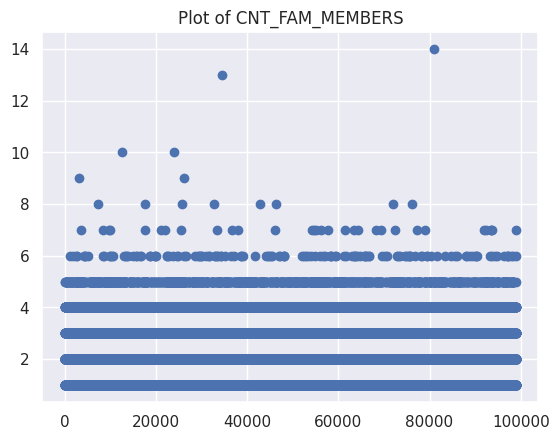

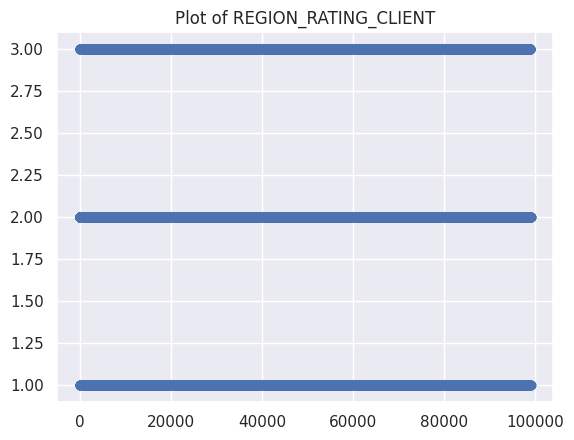

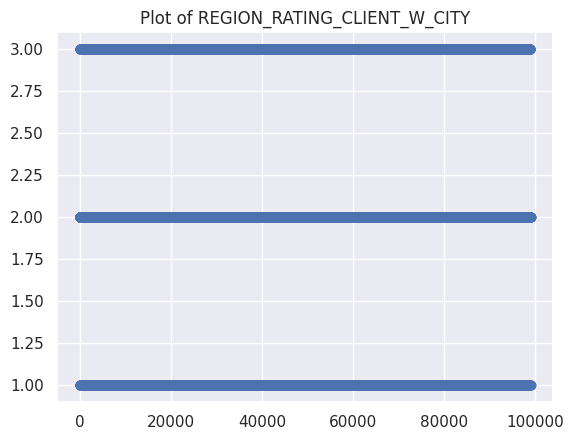

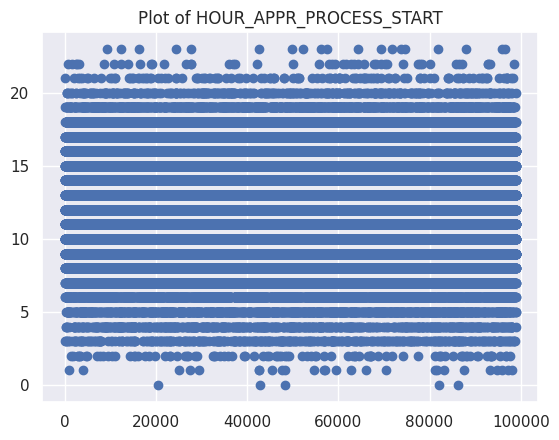

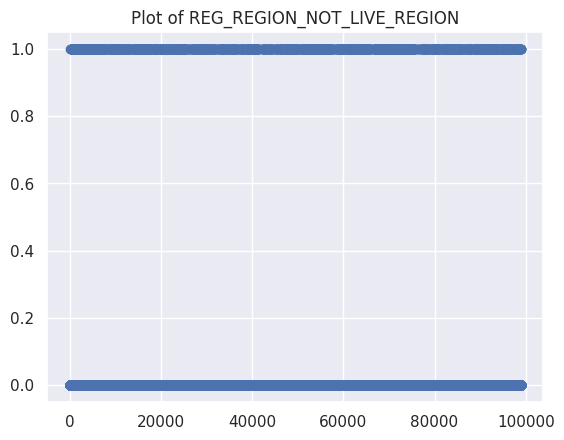

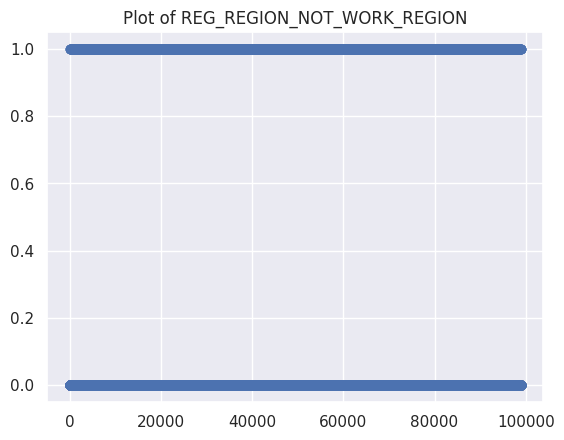

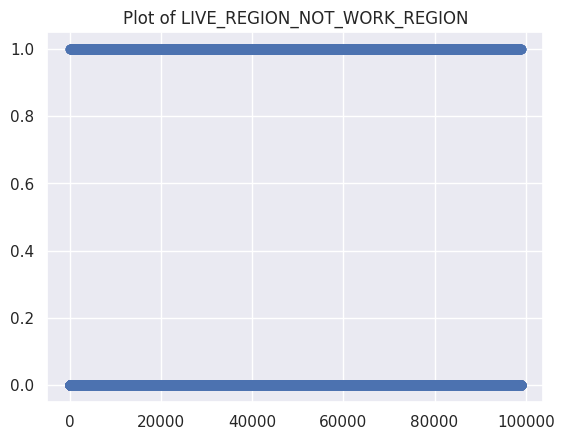

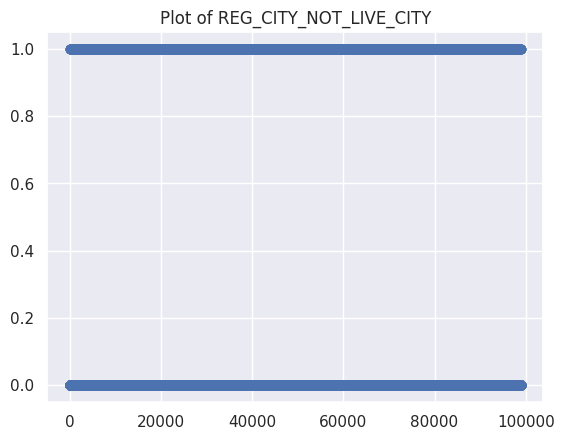

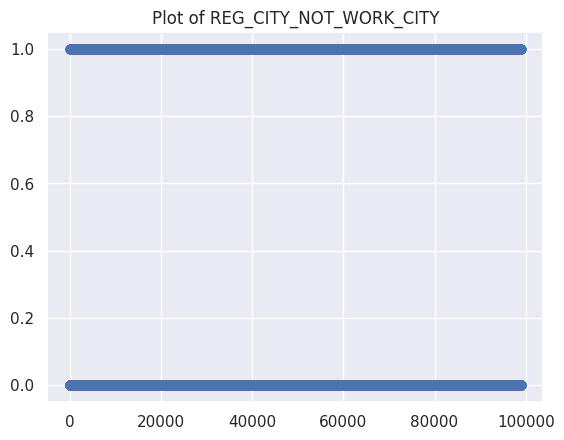

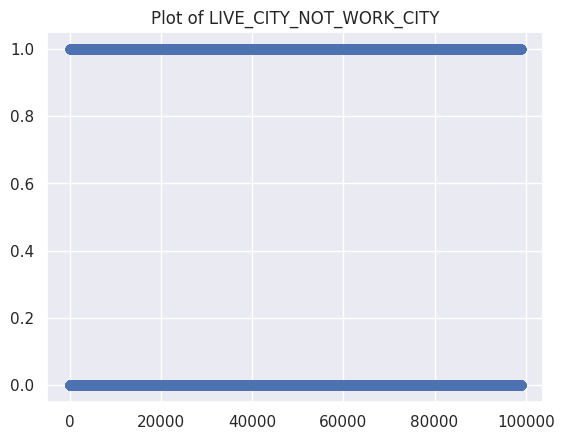

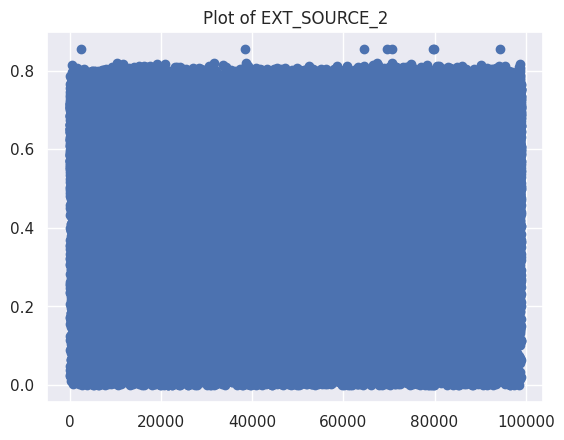

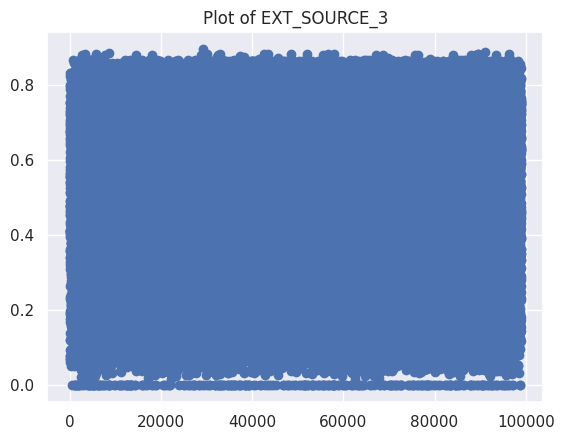

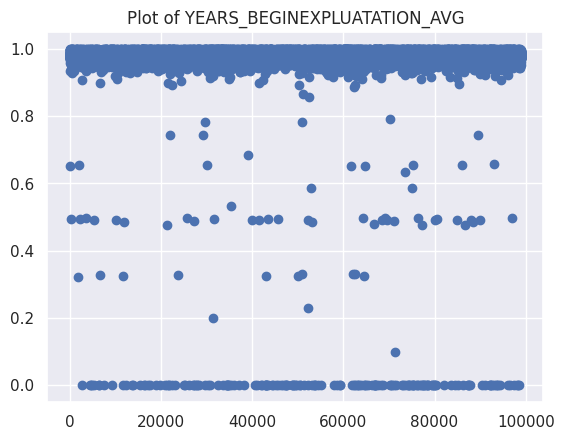

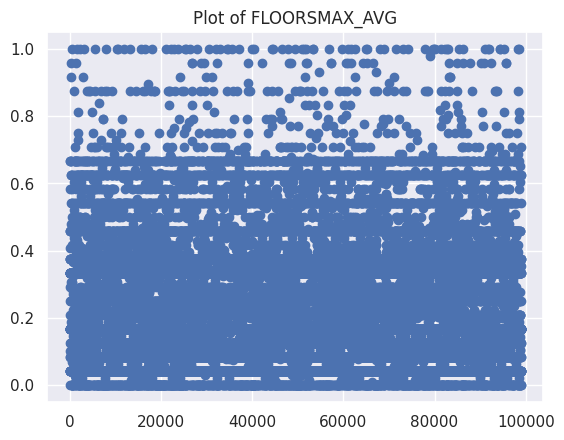

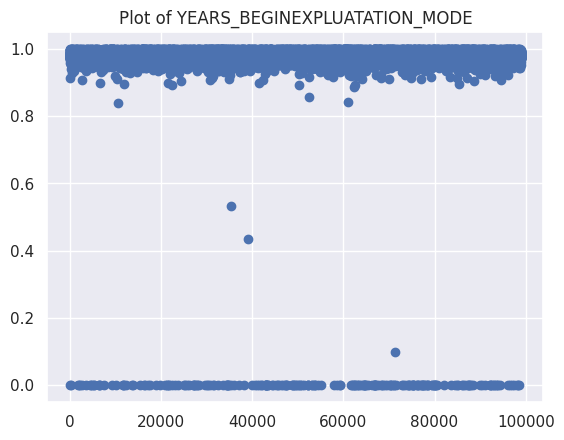

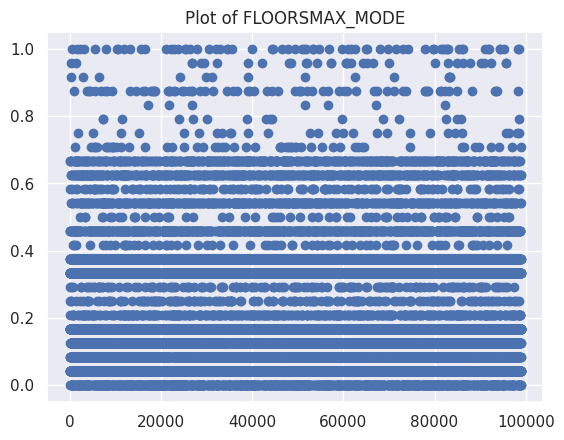

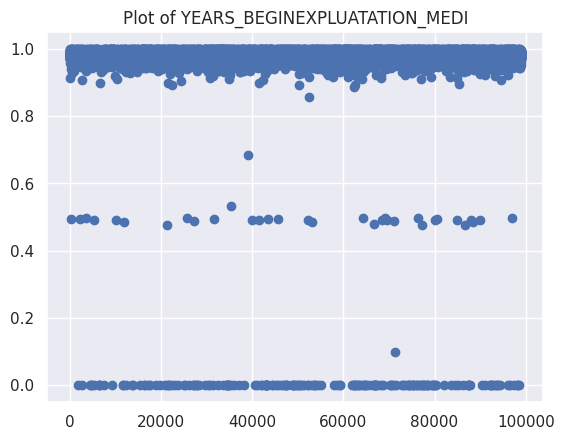

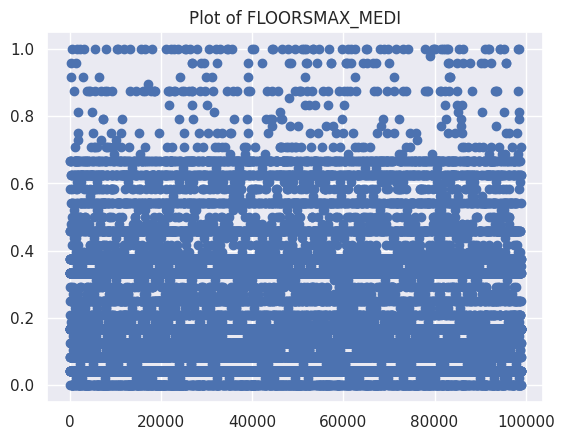

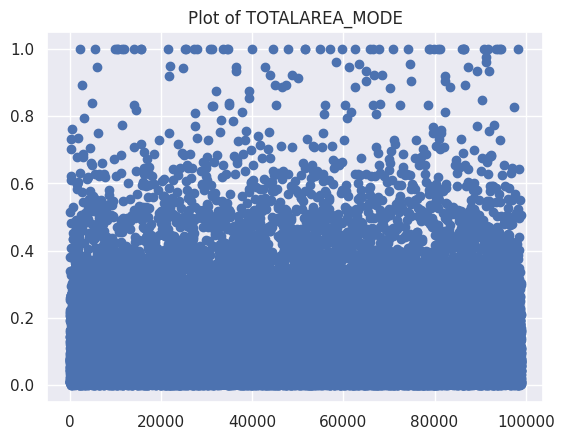

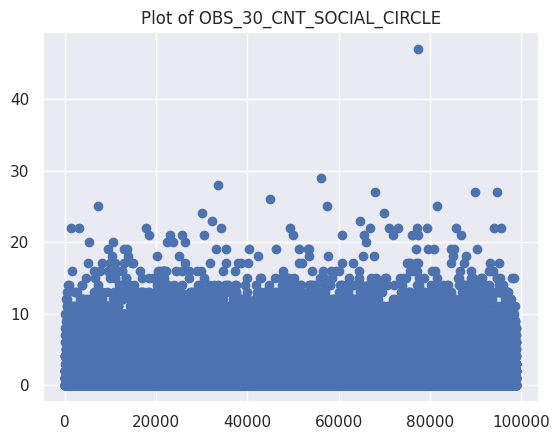

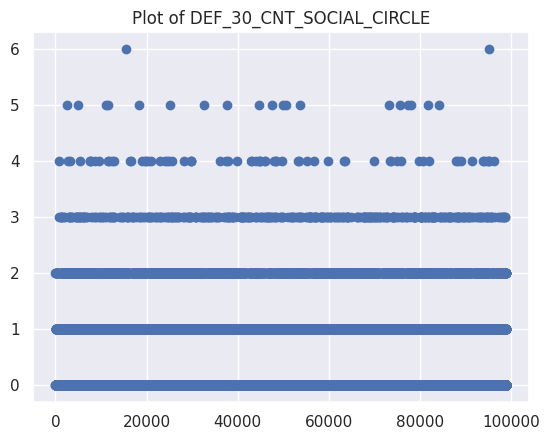

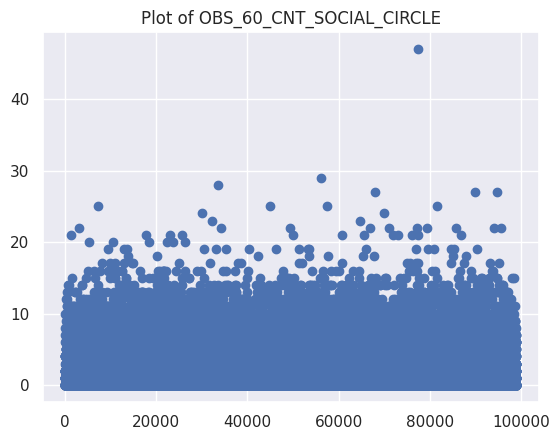

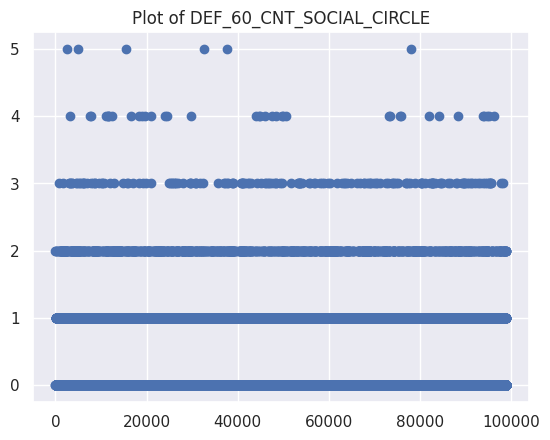

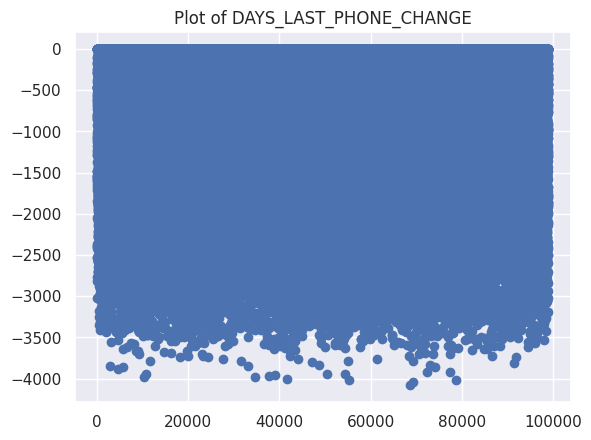

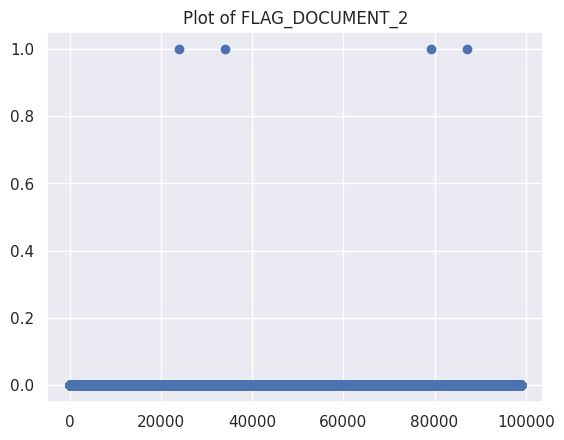

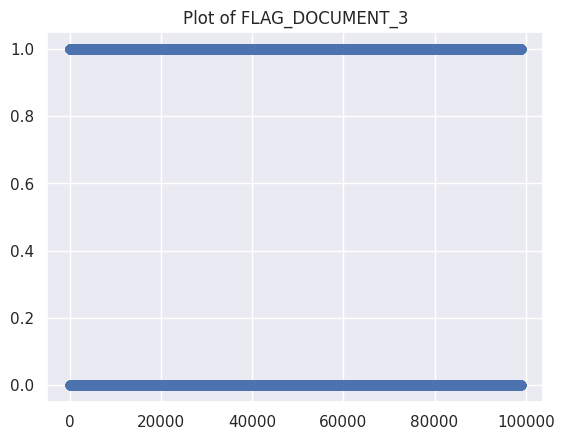

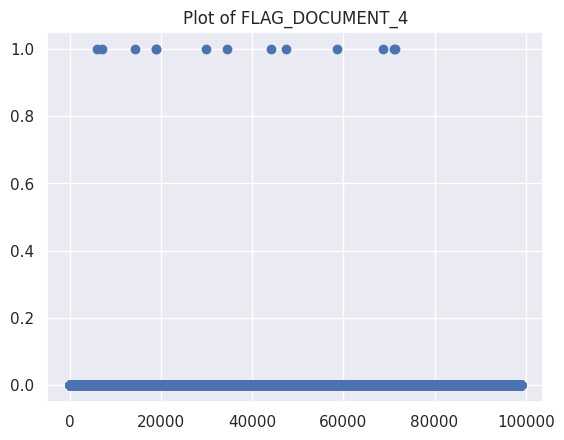

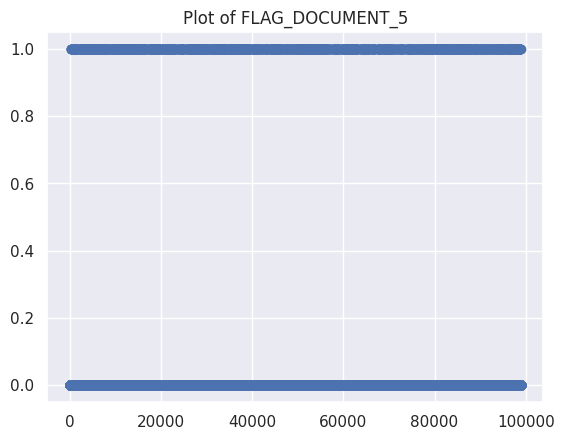

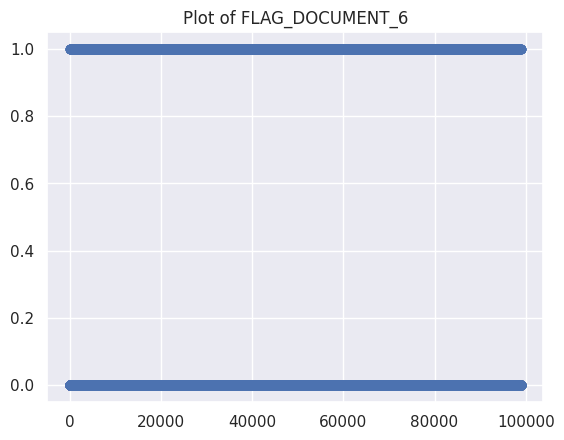

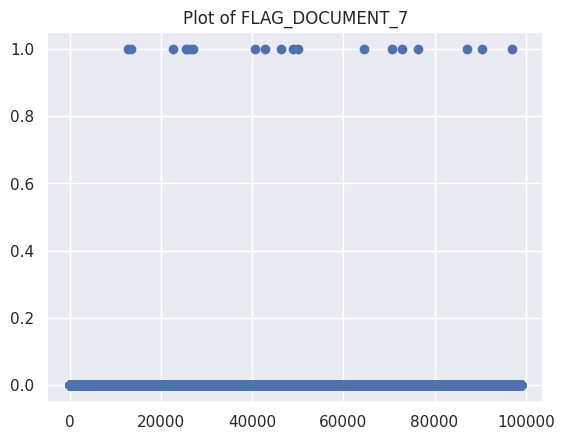

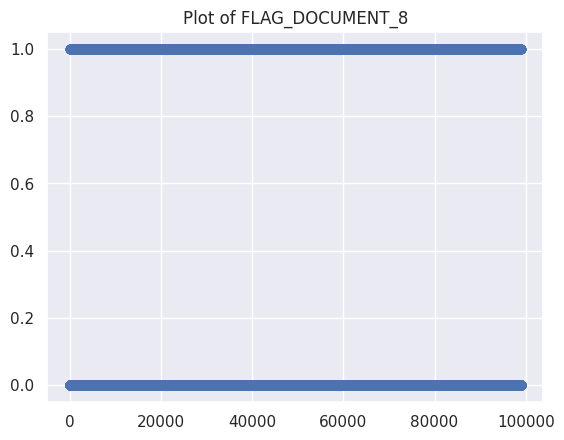

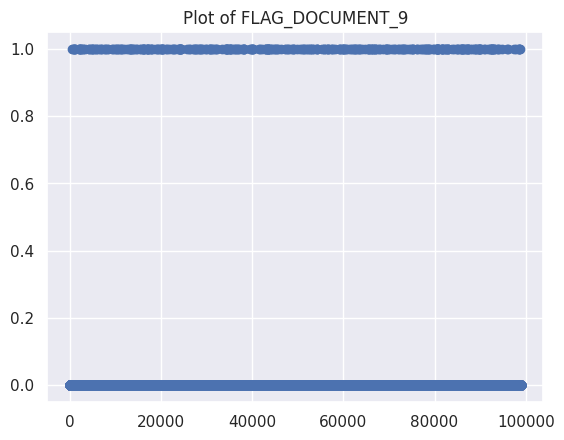

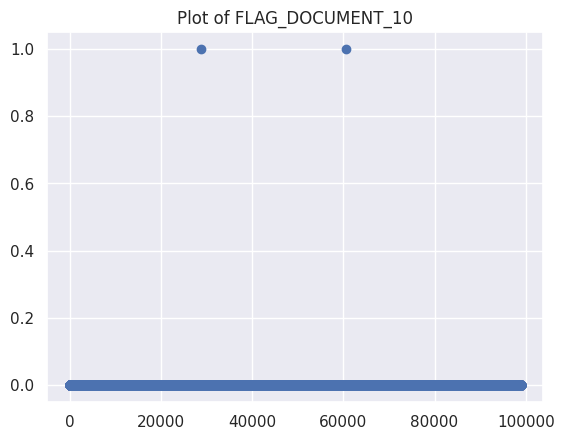

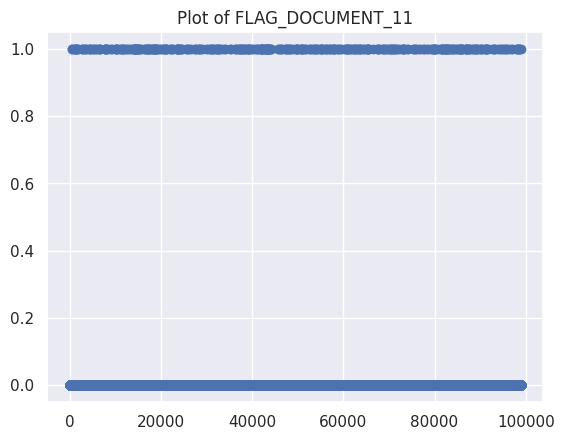

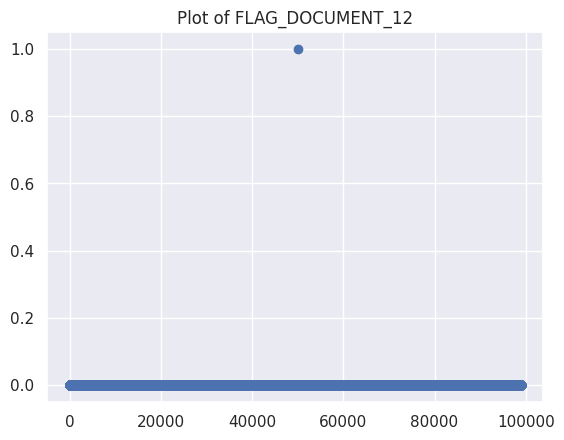

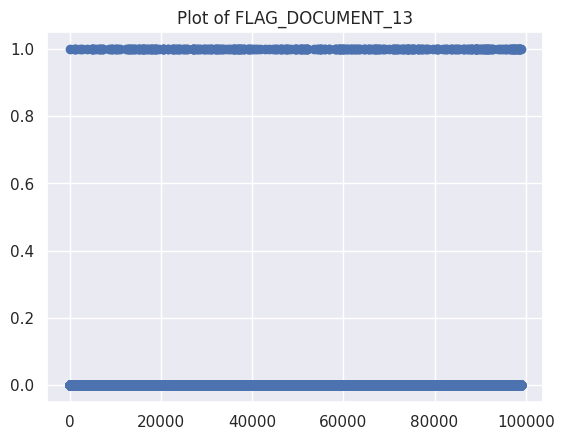

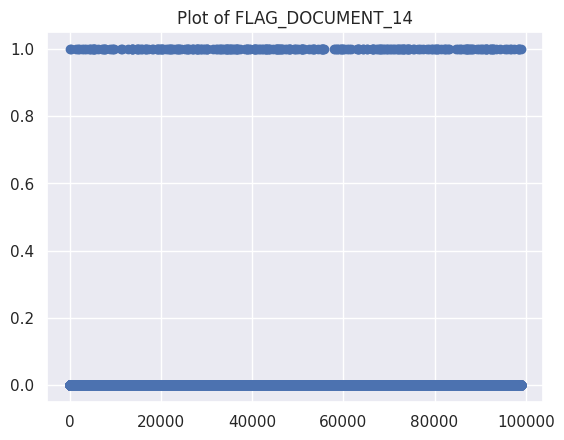

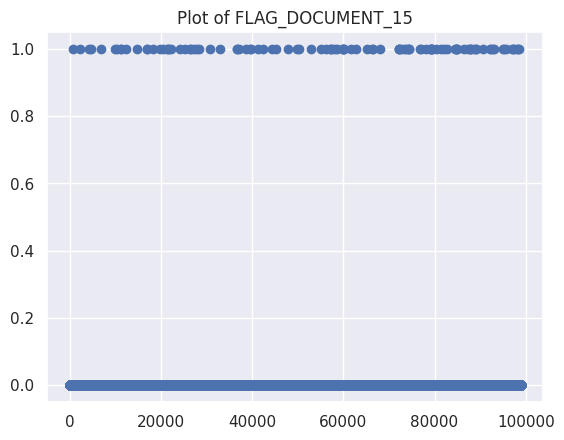

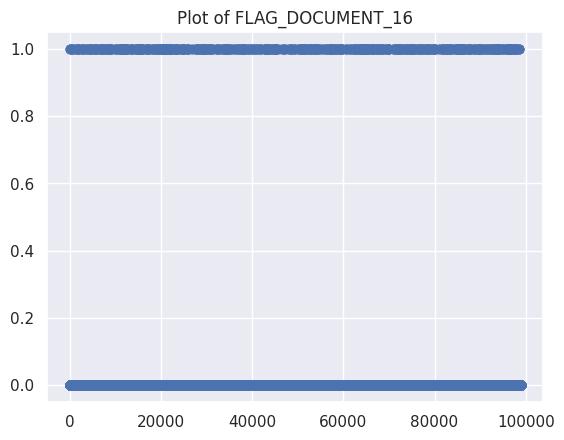

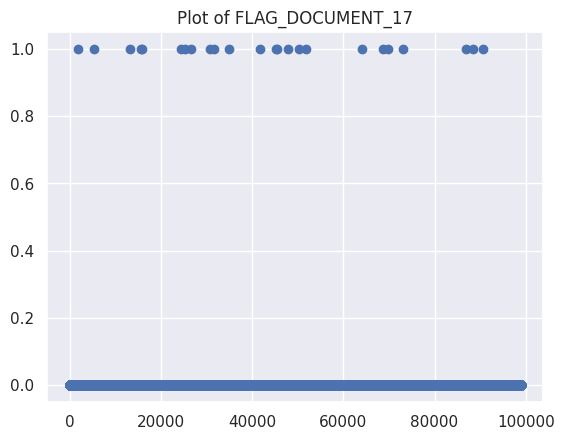

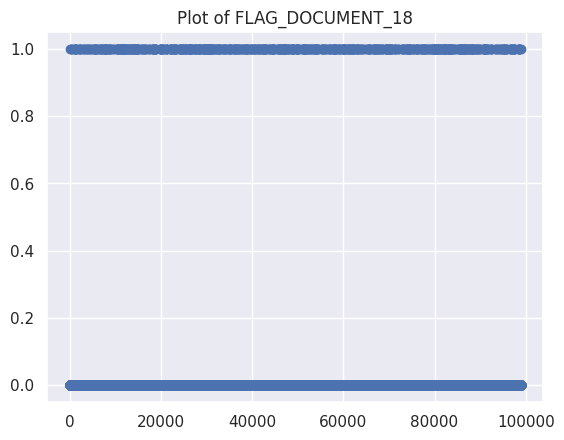

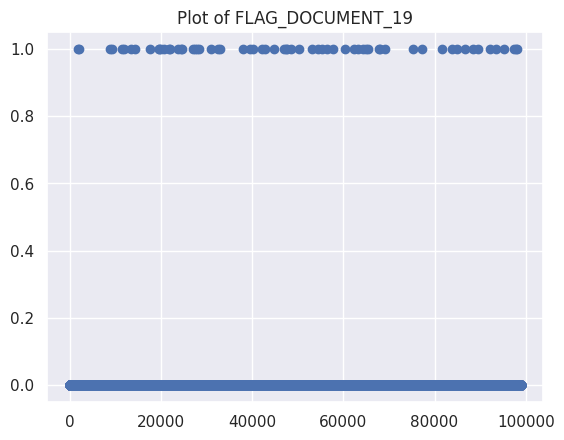

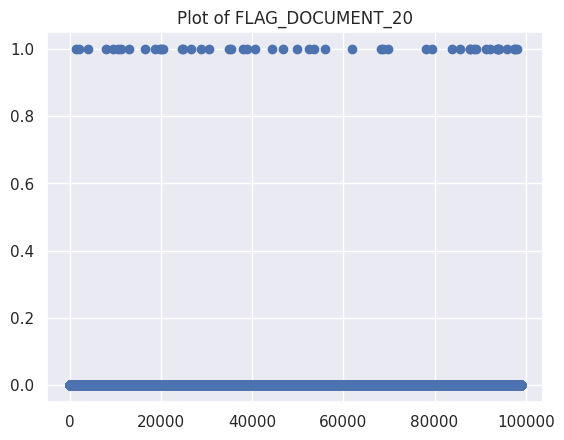

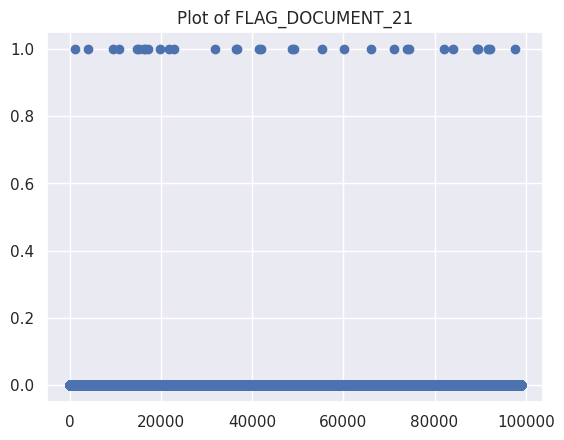

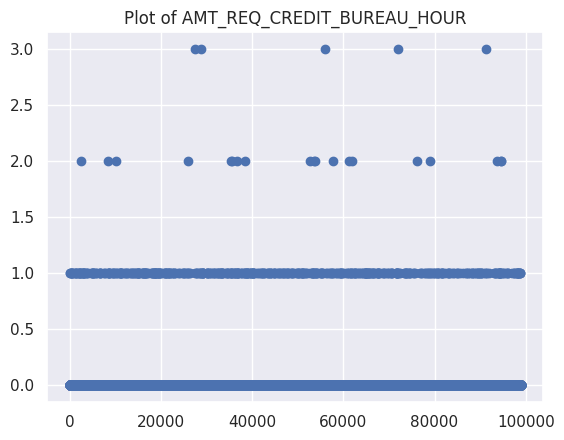

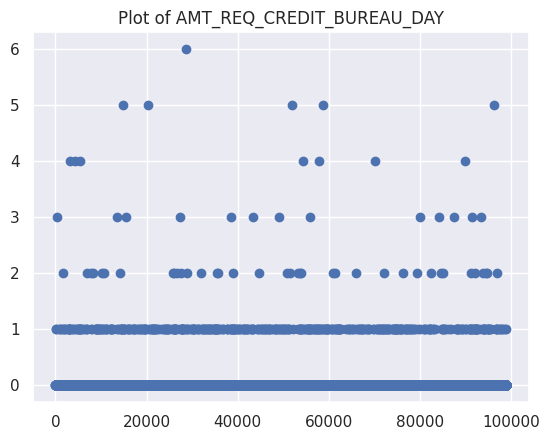

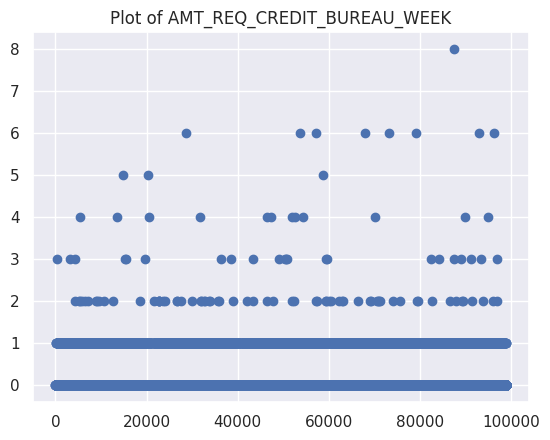

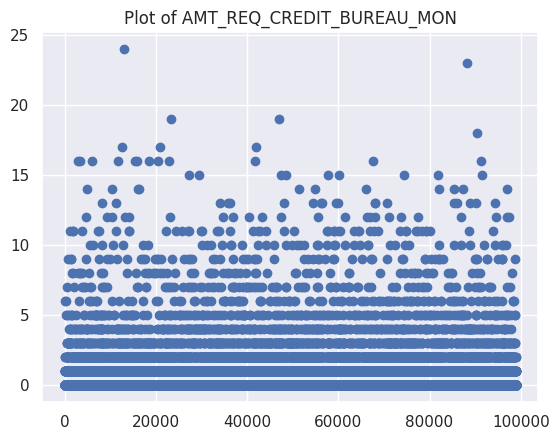

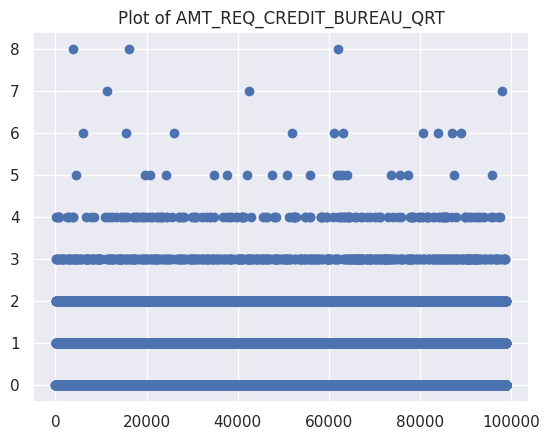

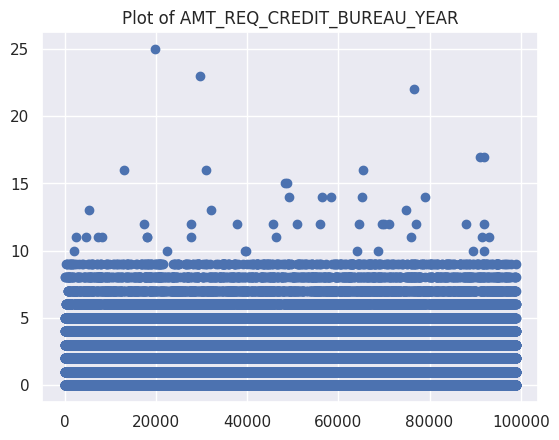

In [ ]:
# Plot each numerical column against the index of the DataFrame 'train'
for column in data_categorical:
    title = "Plot of " + column
    plt.scatter(data.index, data[column])
    plt.title(title)
    plt.show()

Outliers are values that are very different from the rest of the data. Whether we remove them or not depends on the business problem we’re trying to solve.

In this case, we’re assuming the data has no mistakes. So instead of deleting these unusual values, we will keep them and note which columns have them.

Hence, rather than eliminating these points, we will highlight the columns containing extreme values for further analysis.

**CNT_CHILDREN**:
- This denotes the number of children a client has. Instances of clients with more than 10 children are considered extreme.

**AMT_INCOME_TOTAL**:
- This represents the client's income. A particular value around 1.2e8 is notably distant from the rest, suggesting it may be an outlier suitable for removal.

**FLAG_MOBILE**:
- This identifies whether a client possesses a mobile phone. Its absence may or may not be considered an outlier.
Other columns such as OBS_30_CNT_SOCIAL_CIRCLE, DEF_30_CNT_SOCIAL_CIRCLE, and OBS_60_CNT_SOCIAL_CIRCLE also merit attention.

#Converting a numerial data to categorical for analysis

<Axes: xlabel='AMT_ANNUITY', ylabel='Density'>

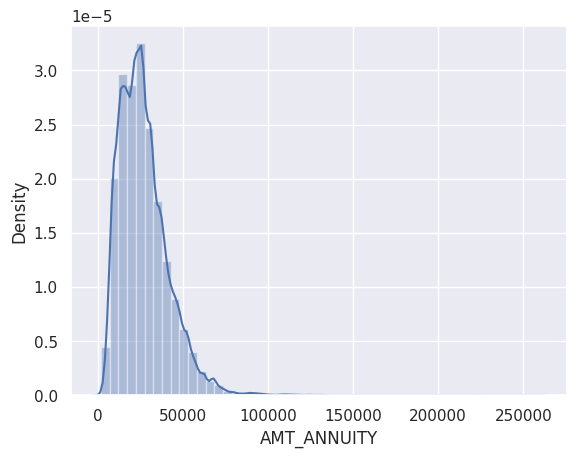

In [ ]:
# Plot a distribution plot for the 'AMT_ANNUITY' column after removing any missing values
sns.distplot(data['AMT_ANNUITY'].dropna())

In [ ]:
def amt_annuity(x):
    if x <= 20000:
        return 'low'
    elif x > 20000 and x <= 50000:
        return 'medium'
    elif x > 50000 and x <= 100000:
        return 'high'
    else:
        return 'very high'

# Apply the 'amt_annuity' function to create a new categorical column 'amt_annuity_categorical'
data['amt_annuity_categorical'] = data['AMT_ANNUITY'].apply(lambda x: amt_annuity(x))

<Axes: xlabel='amt_annuity_categorical', ylabel='count'>

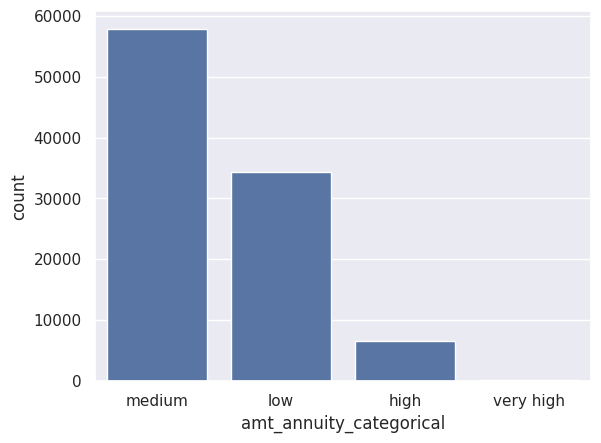

In [ ]:
# Plot a count plot of the 'amt_annuity_categorical' column
sns.countplot(x='amt_annuity_categorical', data= data)

### Reading the another Dataset

In [ ]:
# Read the CSV file 'previous_application.csv' into a DataFrame.
previous_application = pd.read_csv('/content/previous_application.csv')

In [ ]:
# Display the first few rows of the DataFrame 'previous_application'.
previous_application.head()

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,...,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,...,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,...,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Get the Dimensions of the DataFrame (number of rows and columns)
previous_application.shape

(742247, 37)

# There are duplicate 'SK_ID_CURR' as a person could have taken loan multiple times

In [ ]:
# Number of unique id in previous application
previous_application.SK_ID_PREV.value_counts()

,count
SK_ID_PREV,
2128365,1
2030495,1
2802425,1
2523466,1
2819243,1
...,...
2257824,1
1715995,1
2579447,1


In [ ]:
# Number of unique id in previous application
previous_application.SK_ID_CURR.value_counts()

,count
SK_ID_CURR,
265681,36
326092,34
173680,33
280586,33
235163,32
...,...
418134,1
102829,1
415861,1


From the information provided, the shape of the previous application dataset is (1670214, 37), and the count of unique SK_ID_PREV entries matches this, standing at 1670214. However, the count of unique SK_ID_CURR entries is significantly lower, at 338857. This discrepancy indicates that the SK_ID_PREV values contain duplicates, suggesting that multiple entries pertain to the same current application ID (SK_ID_CURR).

#Task 6 - Merging Datasets

# Merging DataFrames: Train and Previous Application Based on SK_ID_PREV

In [ ]:
# Merge 'data' DataFrame with 'previous_application' DataFrame based on 'SK_ID_CURR'
# Using 'inner' join to retain only common rows between the two DataFrames
previous_data = data.merge(previous_application, left_on='SK_ID_CURR', right_on='SK_ID_CURR', how='inner')

previous_data.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE_x,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT_x,AMT_ANNUITY_x,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,XNA,12.0,low_normal,Cash X-Sell: low,365243.0,-716.0,-386.0,-536.0,-527.0,1.0
1,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,XNA,48.0,low_normal,Cash X-Sell: low,365243.0,-151.0,1259.0,-151.0,-143.0,0.0
2,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,XNA,NaN,XNA,Card Street,NaN,NaN,NaN,NaN,NaN,NaN
3,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,Consumer electronics,18.0,high,Cash Street: high,365243.0,-834.0,-324.0,-354.0,-347.0,0.0
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,XNA,48.0,middle,Cash X-Sell: middle,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Getting the names of all columns
previous_application.columns.values

array(['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY',
       'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT',
       'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START',
       'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT',
       'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT',
       'RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED',
       'NAME_CASH_LOAN_PURPOSE', 'NAME_CONTRACT_STATUS', 'DAYS_DECISION',
       'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON', 'NAME_TYPE_SUITE',
       'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY', 'NAME_PORTFOLIO',
       'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE', 'SELLERPLACE_AREA',
       'NAME_SELLER_INDUSTRY', 'CNT_PAYMENT', 'NAME_YIELD_GROUP',
       'PRODUCT_COMBINATION', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE',
       'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION',
       'NFLAG_INSURED_ON_APPROVAL'], dtype=object)

# The merged dataframe also has multiple values for SK_ID_CURR

In [ ]:
# Count the occurrences of each unique value in the 'SK_ID_CURR' column and display the top values
previous_application['SK_ID_CURR'].value_counts().head()

,count
SK_ID_CURR,
265681,36
326092,34
173680,33
280586,33
235163,32


Segregating the dataset on Target = 0 and Target = 1

In [ ]:
# Create a subset of the DataFrame 'data' containing records where the 'TARGET' column is equal to '0'
data_0 = data.loc[train['TARGET'] == '0']

# Create a subset of the DataFrame 'data' containing records where the 'TARGET' column is equal to '1'
data_1 = data.loc[train['TARGET'] == '1']

In [ ]:
# Create a subset of the DataFrame 'previous_data' containing records where the 'TARGET' column is equal to '0'
pdata_0 = previous_data.loc[previous_data['TARGET'] == '0']

# Create a subset of the DataFrame 'previous_data' containing records where the 'TARGET' column is equal to '1'
pdata_1 = previous_data.loc[previous_data['TARGET'] == '1']

# Plotting data

In [ ]:
def plotting(column,hue):
  # Assign column and hue parameters to local variables
    col = column
    hue = hue

  # Create a figure for the plots with a specific size
    fig = plt.figure(figsize=(13,10))

   # Subplot 1: Pie chart showing the distribution of values in the column
    ax1 = plt.subplot(2,2,1)
    data[column].value_counts().plot.pie(autopct="%1.0f%%", ax=ax1)
    plt.title('Distribution of values for the column: '+ column)

    # Subplot 2: Bar plot displaying the distribution of values by target categories
    ax2 = plt.subplot(2,2,2)
    df = pd.DataFrame()
    df['0'] = ((data_0[column].value_counts()) / len(data_0))
    df['1'] = ((data_1[column].value_counts()) / len(data_1))
    df.plot.bar(ax=ax2)
    plt.title('Distribution of values by target category')

    # Subplot 3: Count plot showing the distribution of values for Target=0
    ax3 = plt.subplot(2,2,3)
    sns.countplot(x=col, hue=hue, data=pdata_0, ax=ax3)
    plt.xticks(rotation=90)
    plt.title('Distribution of values for Target=0')

     # Subplot 4: Count plot showing the distribution of values for Target=1
    ax4 = plt.subplot(2,2,4)
    sns.countplot(x=col, hue=hue, data=pdata_1, ax=ax4)
    plt.xticks(rotation=90)
    plt.title('Distribution of values for Target=1')

    # Adjust layout to prevent overlap
    fig.tight_layout()

    # Display the plots
    plt.show()

#Task 7 - Bivariate Analysis

Here, plotting only for specific columns, as plotting in loop for all columns is pretty heavy for this size of dataset.

###Plotting NAME_CONTRACT_STATUS

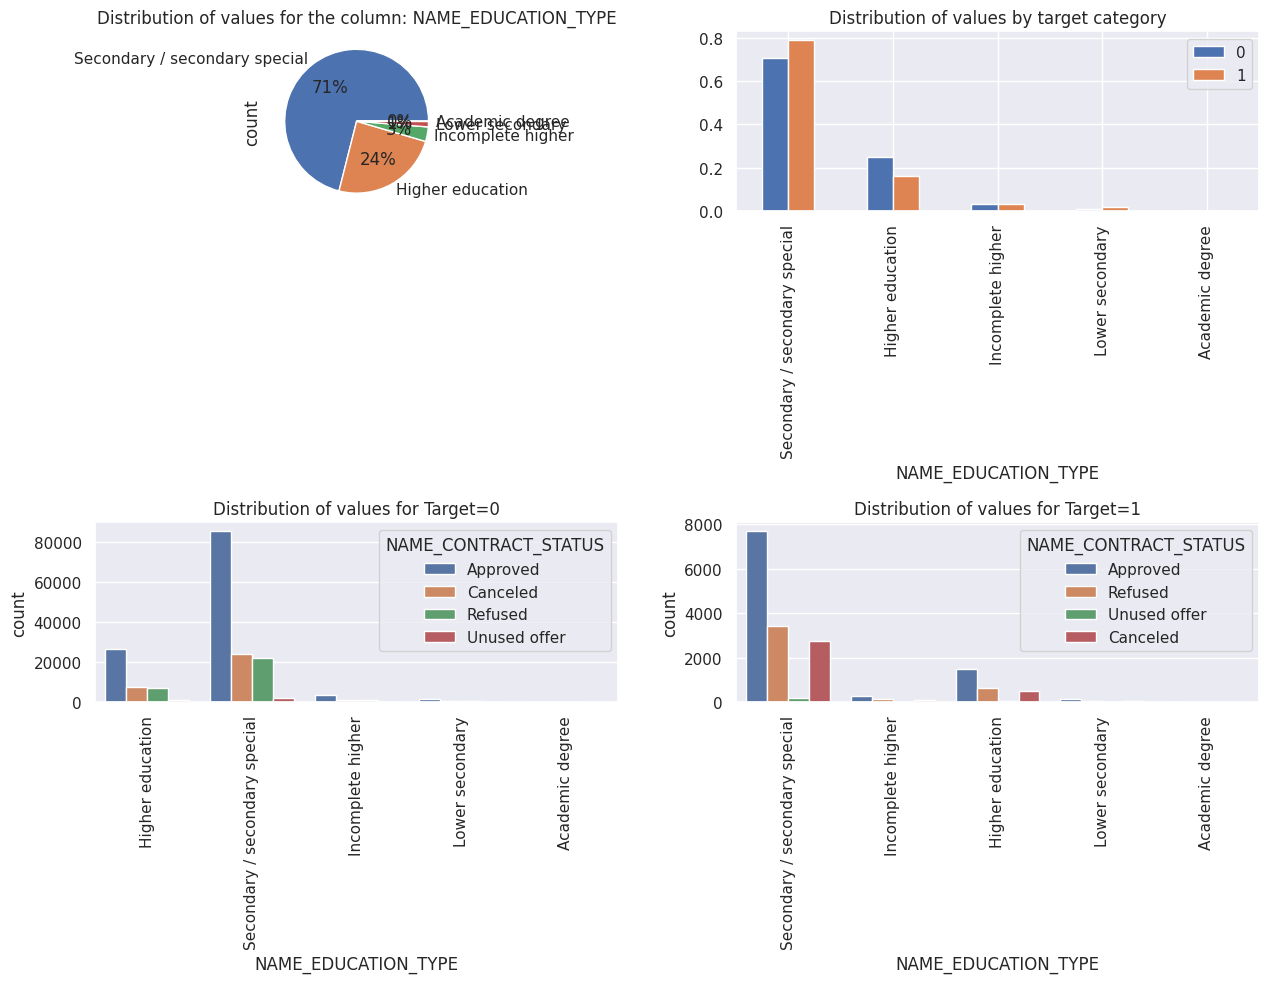

In [ ]:
plotting('NAME_EDUCATION_TYPE','NAME_CONTRACT_STATUS')

Observation: People tend to make more loan for 'Secondary special' and their loan is also approved.




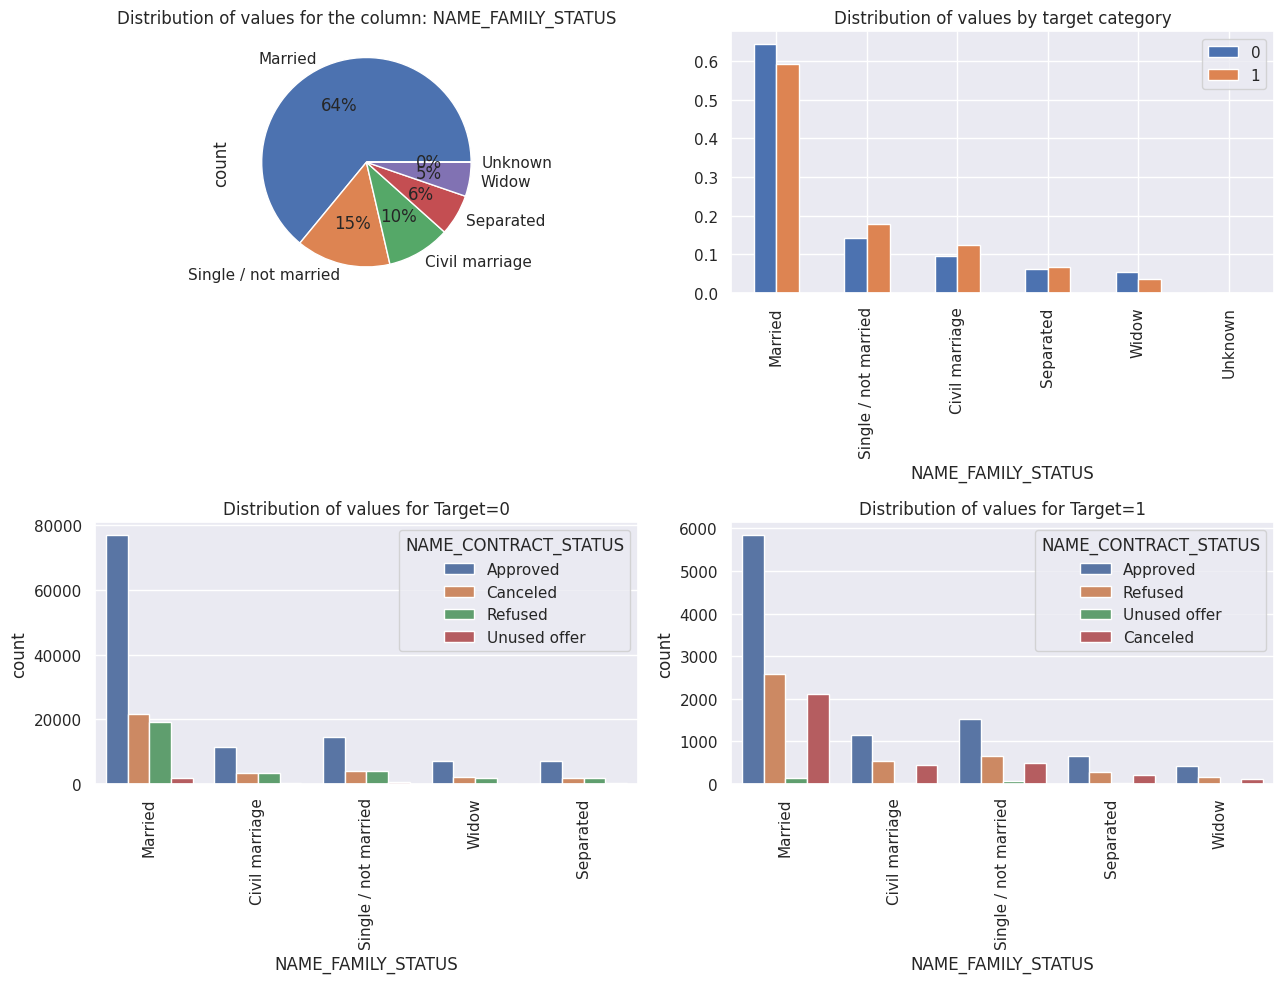

In [ ]:
plotting('NAME_FAMILY_STATUS','NAME_CONTRACT_STATUS')

Observation: Married people are more likely to pay back their loans on time compared to single people, as indicated by the differences in loan approval statuses

#Conclusion
Through the series of tasks performed in this practice session, we gained valuable insights into the loan applicant dataset. We successfully identified missing values, explored the distribution of variables, analyzed outliers, and examined relationships between different attributes.

Moving forward, these insights can guide decision-making processes, such as developing predictive models or refining loan approval criteria, ultimately enhancing the effectiveness of lending practices and minimizing default risks.